# **IMPORT DATA**

### Hubungkan (Mount) Google Drive ke Colab



In [34]:
from google.colab import drive
import os
import pandas as pd
import json

# Mount Google Drive
drive.mount('/content/drive')

# Tentukan path ke folder SB-P12
# Sesuaikan path ini jika letak folder SB-P12 Anda berada di dalam folder lain (misal: 'My Drive/Class/SB-P12')
folder_path = '/content/drive/My Drive/SB-P12'

print("Isi folder SB-P12:")
try:
    display(os.listdir(folder_path))
except FileNotFoundError:
    print(f"Folder tidak ditemukan pada path: {folder_path}. Pastikan nama folder dan lokasinya sudah benar!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Isi folder SB-P12:


['swiftbite_restaurants.csv',
 'swiftbite_order_items.csv',
 'swiftbite_payments.txt',
 'swiftbite_orders.xlsx',
 'swiftbite_customers.json',
 'swiftbite_final_cleaned.csv']

### Membaca Masing-Masing Format File

Berikut adalah cara membaca file `csv`, `xlsx`, `json`, dan `txt` menggunakan library `pandas` dan fungsi bawaan Python.

In [35]:
# Membaca ke-5 file sesuai nama aslinya di folder SB-P12

# 1. Membaca file CSV: swiftbite_restaurants.csv
try:
    df_restaurants = pd.read_csv(os.path.join(folder_path, 'swiftbite_restaurants.csv'))
    print("\n--- File CSV (Restaurants) Berhasil Dimuat ---")
    display(df_restaurants.head(2))
except Exception as e:
    print(f"Gagal membaca CSV Restaurants: {e}")

# 2. Membaca file CSV: swiftbite_order_items.csv
try:
    df_order_items = pd.read_csv(os.path.join(folder_path, 'swiftbite_order_items.csv'))
    print("\n--- File CSV (Order Items) Berhasil Dimuat ---")
    display(df_order_items.head(2))
except Exception as e:
    print(f"Gagal membaca CSV Order Items: {e}")

# 3. Membaca file XLSX (Excel): swiftbite_orders.xlsx
try:
    df_orders = pd.read_excel(os.path.join(folder_path, 'swiftbite_orders.xlsx'))
    print("\n--- File XLSX (Orders) Berhasil Dimuat ---")
    display(df_orders.head(2))
except Exception as e:
    print(f"Gagal membaca XLSX Orders: {e}")

# 4. Membaca file JSON: swiftbite_customers.json
try:
    with open(os.path.join(folder_path, 'swiftbite_customers.json'), 'r') as f:
        data_customers = json.load(f)
    print("\n--- File JSON (Customers) Berhasil Dimuat ---")
    # Tampilkan representasi ringkas atau diconvert ke DataFrame jika formatnya sesuai
    df_customers = pd.DataFrame(data_customers)
    display(df_customers.head(2))
except Exception as e:
    print(f"Gagal membaca JSON Customers: {e}")

# 5. Membaca file TXT (Plain Text): swiftbite_payments.txt
try:
    with open(os.path.join(folder_path, 'swiftbite_payments.txt'), 'r', encoding='utf-8') as f:
        teks_payments = f.read()
    print("\n--- File TXT (Payments) Berhasil Dimuat ---")
    print(teks_payments[:300], "...") # Menampilkan 300 karakter pertama
except Exception as e:
    print(f"Gagal membaca TXT Payments: {e}")


--- File CSV (Restaurants) Berhasil Dimuat ---


,restaurant_id,restaurant_name,cuisine_type,restaurant_zone,price_tier,onboarding_date,active_status
0,R0001,SwiftBite Partner 01,Asian,Central,Premium,2024-09-28,active
1,R0002,SwiftBite Partner 02,Western,Central,Mid,2024-03-15,active



--- File CSV (Order Items) Berhasil Dimuat ---


,order_item_id,order_id,line_number,item_name,item_category,quantity,unit_price,line_discount,line_amount
0,OI00001,O00001,1,Pudding,Dessert,1,16000,2000,14000
1,OI00002,O00001,2,Juice,Drink,2,20000,0,40000



--- File XLSX (Orders) Berhasil Dimuat ---


,order_id,customer_id,restaurant_id,order_timestamp,order_status,promo_code,subtotal_amount,delivery_fee,discount_amount,total_amount
0,O00001,C0080,R0018,2026-01-19 03:32:00,completed,NaN,54000,18000,10000,62000
1,O00002,C0087,R0023,2026-01-10 18:34:00,completed,NEWUSER,130000,18000,15000,133000



--- File JSON (Customers) Berhasil Dimuat ---


,customer_id,full_name,email,phone_number,signup_date,customer_zone,customer_segment
0,C0001,Tio Hidayat,tiohidayat1@example.com,082376113984,2025-12-03,East,Loyal
1,C0002,Eka Hidayat,ekahidayat2@example.com,087534238072,2025-08-08,Central,Loyal



--- File TXT (Payments) Berhasil Dimuat ---
payment_id|order_id|payment_method|payment_status|payment_amount|payment_timestamp|attempt_number
P00001|O00001|e_wallet|successful|62000|2026-01-19 03:35:00|1
P00002|O00002|bank_transfer|successful|133000|2026-01-10 18:37:00|1
P00003|O00003|credit_card|successful|233000|2026-01-12 07:42:00|1
P00004 ...


### Parsing Data Payments (TXT) ke DataFrame

Karena data `swiftbite_payments.txt` dipisahkan menggunakan tanda pipa (`|`), kita ubah terlebih dahulu menjadi DataFrame agar mempermudah analisis.

In [36]:
import io

# Membaca teks payments menggunakan pd.read_csv dengan delimiter '|'
df_payments = pd.read_csv(io.StringIO(teks_payments), sep='|')
print("Data Payments berhasil diubah ke DataFrame.")
display(df_payments.head(2))

Data Payments berhasil diubah ke DataFrame.


,payment_id,order_id,payment_method,payment_status,payment_amount,payment_timestamp,attempt_number
0,P00001,O00001,e_wallet,successful,62000,2026-01-19 03:35:00,1
1,P00002,O00002,bank_transfer,successful,133000,2026-01-10 18:37:00,1


# **PROFILING**

### Profiling Masing-Masing Dataset

Kita akan melihat ringkasan dimensi (shape), tipe data tiap kolom, jumlah baris yang kosong (null), serta sampel data dari ke-5 dataset.

In [37]:
datasets = {
    "Restaurants": df_restaurants,
    "Order Items": df_order_items,
    "Orders": df_orders,
    "Customers": df_customers,
    "Payments": df_payments
}

for name, df in datasets.items():
    print("=" * 50)
    print(f" PROFILING DATASET: {name.upper()} ")
    print("=" * 50)

    # 1. Dimensi Data
    print(f"Jumlah Baris: {df.shape[0]}")
    print(f"Jumlah Kolom: {df.shape[1]}")
    print("\n--- Informasi Kolom & Tipe Data ---")

    # 2. Info Kolom
    info_df = pd.DataFrame({
        'Tipe Data': df.dtypes,
        'Jumlah Non-Null': df.notnull().sum(),
        'Jumlah Null': df.isnull().sum(),
        '% Null': (df.isnull().sum() / len(df) * 100).round(2)
    })
    display(info_df)

    # 3. Statistik Deskriptif singkat untuk numerik
    num_cols = df.select_dtypes(include=['number']).columns
    if len(num_cols) > 0:
        print("\n--- Statistik Deskriptif Kolom Numerik ---")
        display(df.describe().round(2))

    print("\n" + "*"*50 + "\n")

 PROFILING DATASET: RESTAURANTS 
Jumlah Baris: 25
Jumlah Kolom: 7

--- Informasi Kolom & Tipe Data ---


,Tipe Data,Jumlah Non-Null,Jumlah Null,% Null
restaurant_id,object,25,0,0.0
restaurant_name,object,25,0,0.0
cuisine_type,object,25,0,0.0
restaurant_zone,object,25,0,0.0
price_tier,object,25,0,0.0
onboarding_date,object,25,0,0.0
active_status,object,25,0,0.0



**************************************************

 PROFILING DATASET: ORDER ITEMS 
Jumlah Baris: 974
Jumlah Kolom: 9

--- Informasi Kolom & Tipe Data ---


,Tipe Data,Jumlah Non-Null,Jumlah Null,% Null
order_item_id,object,974,0,0.0
order_id,object,974,0,0.0
line_number,int64,974,0,0.0
item_name,object,974,0,0.0
item_category,object,974,0,0.0
quantity,object,974,0,0.0
unit_price,int64,974,0,0.0
line_discount,int64,974,0,0.0
line_amount,int64,974,0,0.0



--- Statistik Deskriptif Kolom Numerik ---


,line_number,unit_price,line_discount,line_amount
count,974.00,974.00,974.00,974.00
mean,2.04,24792.61,1436.34,52886.04
std,0.99,17136.06,1969.33,41813.35
min,1.00,9000.00,0.00,4000.00
25%,1.00,18000.00,0.00,28000.00
50%,2.00,22000.00,0.00,48000.00
75%,3.00,28000.00,2000.00,66750.00
max,5.00,488000.00,5000.00,976000.00


... (7 outputs left out)

,Tipe Data,Jumlah Non-Null,Jumlah Null,% Null
payment_id,object,381,0,0.0
order_id,object,381,0,0.0
payment_method,object,381,0,0.0
payment_status,object,381,0,0.0
payment_amount,int64,381,0,0.0
payment_timestamp,object,381,0,0.0
attempt_number,int64,381,0,0.0



--- Statistik Deskriptif Kolom Numerik ---


,payment_amount,attempt_number
count,381.00,381.00
mean,152076.12,1.08
std,84246.99,0.27
min,7000.00,1.00
25%,98000.00,1.00
50%,142000.00,1.00
75%,192000.00,1.00
max,1098000.00,2.00



**************************************************



### Profiling Mendalam & Deteksi Anomali Data

Kita akan menjalankan pengecekan sistematis berdasarkan kriteria:
1. **Format Tanggal** (Konsistensi format penulisan tanggal)
2. **Tipe Data & Nilai Hilang** (Pengecekan tipe kolom yang tidak sesuai dan missing/placeholder values)
3. **Konsistensi Kategori** (Mencari spasi berlebih atau variasi penulisan teks)
4. **Duplikasi Data / Kunci Utama** (Pengecekan ID unik)
5. **Angka Mencurigakan & Outlier** (Nilai negatif yang tidak masuk akal atau pencilan ekstrim)
6. **Inkonsistensi Antar-Tabel** (Referential integrity antar-tabel)

In [38]:
print("=== 1. PENGECEKAN TANGGAL & TIPE DATA ===")
# Cek tipe data tanggal di df_restaurants (onboarding_date)
print("Restaurants (onboarding_date) sample:", df_restaurants['onboarding_date'].head(3).tolist())
# Cek tipe data tanggal di df_orders (order_timestamp)
print("Orders (order_timestamp) sample:", df_orders['order_timestamp'].head(3).tolist())
# Cek tipe data tanggal di df_customers (signup_date)
print("Customers (signup_date) sample:", df_customers['signup_date'].head(3).tolist())
# Cek tipe data tanggal di df_payments (payment_timestamp)
print("Payments (payment_timestamp) sample:", df_payments['payment_timestamp'].head(3).tolist())

print("\n=== 2. PENGECEKAN DUPLIKAT KUNCI UTAMA (PRIMARY KEY) ===")
print(f"Restaurants - 'restaurant_id' duplikat: {df_restaurants['restaurant_id'].duplicated().sum()}")
print(f"Orders - 'order_id' duplikat: {df_orders['order_id'].duplicated().sum()}")
print(f"Customers - 'customer_id' duplikat: {df_customers['customer_id'].duplicated().sum()}")
print(f"Payments - 'payment_id' duplikat: {df_payments['payment_id'].duplicated().sum()}")
print(f"Order Items - 'order_item_id' duplikat: {df_order_items['order_item_id'].duplicated().sum()}")

print("\n=== 3. PENGECEKAN NILAI UNIK & KONSISTENSI KATEGORI ===")
print("Cuisine Types:", df_restaurants['cuisine_type'].unique())
print("Order status:", df_orders['order_status'].unique())
print("Restaurant Zones:", df_restaurants['restaurant_zone'].unique())
print("Price Tiers:", df_restaurants['price_tier'].unique())
print("Active Status:", df_restaurants['active_status'].unique())
print("Payment Methods:", df_payments['payment_method'].unique())
print("Payment Status:", df_payments['payment_status'].unique())
print("Customer Zones:", df_customers['customer_zone'].unique())
print("Customer Segments:", df_customers['customer_segment'].unique())

print("\n=== 4. PENGECEKAN NILAI NUMERIK MENCURIGAKAN & OUTLIER ===")
print("Order Items - Quantity unique values:", df_order_items['quantity'].unique())
# Cek apakah ada unit_price, line_discount, atau line_amount bernilai negatif
print("Order Items - Minus unit price:", (df_order_items['unit_price'] < 0).sum())
print("Order Items - Minus discount:", (df_order_items['line_discount'] < 0).sum())
print("Order Items - Minus amount:", (df_order_items['line_amount'] < 0).sum())
print("Payments - Minus payment amount:", (df_payments['payment_amount'] < 0).sum())

print("\n=== 5. PENGECEKAN INTEGRITAS ANTAR-TABEL (CROSS-TABLE) ===")
# Cek apakah ada order_id di Order Items yang tidak ada di tabel Orders
missing_orders_items = ~df_order_items['order_id'].isin(df_orders['order_id'])
print(f"Order Items dengan order_id asing (tidak ada di Orders): {missing_orders_items.sum()}")
# Cek apakah ada order_id di Payments yang tidak ada di tabel Orders
missing_payments_orders = ~df_payments['order_id'].isin(df_orders['order_id'])
print(f"Payments dengan order_id asing (tidak ada di Orders): {missing_payments_orders.sum()}")
# Cek apakah ada customer_id di Orders yang tidak ada di tabel Customers
missing_customer_orders = ~df_orders['customer_id'].isin(df_customers['customer_id'])
print(f"Orders dengan customer_id asing (tidak ada di Customers): {missing_customer_orders.sum()}")

=== 1. PENGECEKAN TANGGAL & TIPE DATA ===
Restaurants (onboarding_date) sample: ['2024-09-28', '2024-03-15', '2025-03-04']
Orders (order_timestamp) sample: ['2026-01-19 03:32:00', '2026-01-10 18:34:00', '2026-01-12 07:39:00']
Customers (signup_date) sample: ['2025-12-03', '2025-08-08', '2025-12-06']
Payments (payment_timestamp) sample: ['2026-01-19 03:35:00', '2026-01-10 18:37:00', '2026-01-12 07:42:00']

=== 2. PENGECEKAN DUPLIKAT KUNCI UTAMA (PRIMARY KEY) ===
Restaurants - 'restaurant_id' duplikat: 0
Orders - 'order_id' duplikat: 0
Customers - 'customer_id' duplikat: 1
Payments - 'payment_id' duplikat: 0
Order Items - 'order_item_id' duplikat: 0

=== 3. PENGECEKAN NILAI UNIK & KONSISTENSI KATEGORI ===
Cuisine Types: ['Asian' 'Western' 'Fast Food' 'Cafe & Beverage' 'Dessert' 'Indonesian']
Order status: ['completed' 'COMPLETED ' 'cancelled']
Restaurant Zones: ['Central' 'South' 'North' 'West' 'East']
Price Tiers: ['Premium' 'Mid' 'Budget' 'MID ']
Active Status: ['active' 'inactive']
Pa

### Ringkasan Temuan Profiling Data (Data Quality Log)

Berikut adalah tabel ringkasan temuan berdasarkan hasil analisis otomatis di atas:

| Finding ID | Dataset | Field Key | Finding Evidence | Why It Matters | Verification Method | Verification Evidence Result | Judgment | Reason for Judgment | Cleaning Rule ID |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **F-01** | `df_customers` | `customer_id` | Terdapat 1 nilai duplikat | Mengacaukan integritas kunci utama (Primary Key) | `duplicated().sum()` | Hasil output menunjukkan nilai `1` | **FIX** | Data pelanggan duplikat harus dihapus/dibersihkan untuk memastikan keunikan data | **CR-01** |
| **F-02** | `df_order_items` | `quantity` | Adanya nilai `'1 pcs'`, `'3 pcs'` di samping angka integer | Menyebabkan kolom dibaca sebagai tipe teks (`object`) sehingga tidak bisa dihitung secara matematis | `unique()` | Nilai unik mengandung string `'1 pcs'` dan `'3 pcs'` | **STANDARDIZE** | Menghilangkan substring `'pcs'` dan mengubah tipe data ke `int` | **CR-02** |
| **F-03** | `df_restaurants` | `price_tier` | Terdapat variasi nilai `'Mid'` dan `'MID '` | Menyebabkan segmentasi bias karena spasi tambahan di akhir string | `unique()` | Nilai unik mengandung `'Mid'` dan `'MID '` | **STANDARDIZE** | Melakukan trim spasi (*strip*) dan mengubah semua karakter menjadi huruf besar/kecil yang seragam | **CR-03** |
| **F-04** | `df_payments` | `payment_method` | Terdapat variasi nilai `'credit_card'`, `'CREDIT CARD '`, `'cash'`, `'CASH '` | Memecah jenis metode pembayaran yang sama menjadi kategori terpisah karena perbedaan spasi dan huruf kapital | `unique()` | Nilai unik mendeteksi variasi penulisan berlebih | **STANDARDIZE** | Mengubah teks menjadi huruf kecil (*lowercase*) dan menghilangkan spasi ekstra di awal/akhir | **CR-04** |
| **F-05** | `df_customers` | `customer_segment` | Terdapat variasi nilai `'New'` dan `'NEW '` | Mengakibatkan segmentasi pelanggan baru terbagi menjadi dua kelompok berbeda | `unique()` | Nilai unik mendeteksi `'New'` dan `'NEW '` | **STANDARDIZE** | Melakukan trim spasi (*strip*) dan menyamakan format penulisan | **CR-05** |
| **F-06** | Semua | *Kolom Tanggal* | Kolom tanggal masih bertipe data string/object | Menghambat fungsi analisis berbasis deret waktu (*time-series*) | `.dtypes` | Bertipe `object` | **STANDARDIZE** | Mengonversi semua kolom tanggal menjadi bertipe `datetime64[ns]` | **CR-06** |
| **F-07** | `df_orders` | `order_status` | Terdapat variasi nilai `'completed'` dan `'COMPLETED '` | Mengakibatkan status order terbagi menjadi dua kelompok berbeda | `unique()` | Nilai unik mendeteksi `'completed'` dan `'COMPLETED'` | **STANDARDIZE** | Melakukan trim spasi (*strip*) dan menyamakan format penulisan | **CR-07** |

# **DATA CLEANING**

### Eksekusi Pembersihan Data (Data Cleaning)

Kita akan menjalankan langkah-langkah pembersihan sesuai rancangan:
*   **CR-01 (Fix Duplicate)**: Menghapus duplikat pada `df_customers` berdasarkan `customer_id`.
*   **CR-02 (Standardize Quantity)**: Menghapus teks `'pcs'` pada kolom `quantity` di `df_order_items` dan mengonversi tipenya ke integer.
*   **CR-03, CR-04, CR-05 (Trim & Unify Categories)**: Menghilangkan spasi tambahan di akhir string (*strip*) serta menstandarkan huruf kapital/kecil pada kolom kategori di `df_restaurants`, `df_payments`, dan `df_customers`.
*   **CR-06 (Datetime Conversion)**: Mengonversi semua kolom penanda waktu menjadi tipe data `datetime`.

In [39]:
# Salin dataset asli agar memiliki backup jika terjadi kesalahan
df_customers_clean = df_customers.copy()
df_order_items_clean = df_order_items.copy()
df_restaurants_clean = df_restaurants.copy()
df_payments_clean = df_payments.copy()
df_orders_clean = df_orders.copy()

print("=== MENJALANKAN CLEANING RULES ===")

# CR-01: Drop duplicates pada tabel Customers berdasarkan customer_id
before_customers = df_customers_clean.shape[0]
df_customers_clean = df_customers_clean.drop_duplicates(subset=['customer_id'], keep='first')
after_customers = df_customers_clean.shape[0]
print(f"[CR-01] Berhasil menghapus {before_customers - after_customers} baris duplikat di df_customers.")

# CR-02: Membersihkan kolom 'quantity' di Order Items
# Hilangkan string ' pcs' lalu ubah tipe data menjadi integer
df_order_items_clean['quantity'] = df_order_items_clean['quantity'].astype(str).str.replace(' pcs', '', case=False).str.strip()
df_order_items_clean['quantity'] = pd.to_numeric(df_order_items_clean['quantity'], errors='coerce').astype(int)
print("[CR-02] Kolom quantity berhasil distandarkan ke tipe data Integer.")

# CR-03: Standarisasi 'price_tier' di Restaurants
df_restaurants_clean['price_tier'] = df_restaurants_clean['price_tier'].astype(str).str.strip().str.capitalize()
print("[CR-03] Kategori 'price_tier' berhasil distandarkan.")

# CR-04: Standarisasi 'payment_method' di Payments
# Ubah semua ke lowercase, ganti spasi jadi underscore jika perlu, lalu hilangkan spasi tambahan
df_payments_clean['payment_method'] = df_payments_clean['payment_method'].astype(str).str.strip().str.lower().str.replace(' ', '_')
print("[CR-04] Kategori 'payment_method' berhasil distandarkan.")

# CR-05: Standarisasi 'customer_segment' di Customers
df_customers_clean['customer_segment'] = df_customers_clean['customer_segment'].astype(str).str.strip().str.capitalize()
print("[CR-05] Kategori 'customer_segment' berhasil distandarkan.")

# CR-06: Mengonversi tipe data kolom tanggal menjadi datetime
df_restaurants_clean['onboarding_date'] = pd.to_datetime(df_restaurants_clean['onboarding_date'], errors='coerce')
df_orders_clean['order_timestamp'] = pd.to_datetime(df_orders_clean['order_timestamp'], errors='coerce')
df_customers_clean['signup_date'] = pd.to_datetime(df_customers_clean['signup_date'], errors='coerce')
df_payments_clean['payment_timestamp'] = pd.to_datetime(df_payments_clean['payment_timestamp'], errors='coerce')
print("[CR-06] Semua kolom berformat tanggal berhasil dikonversi ke tipe Datetime.")

# CR-07: Standarisasi 'order_status' di Orders
df_orders_clean['order_status'] = df_orders_clean['order_status'].astype(str).str.strip().str.lower()
print("[CR-07] Kategori 'order_status' berhasil distandarkan.")

=== MENJALANKAN CLEANING RULES ===
[CR-01] Berhasil menghapus 1 baris duplikat di df_customers.
[CR-02] Kolom quantity berhasil distandarkan ke tipe data Integer.
[CR-03] Kategori 'price_tier' berhasil distandarkan.
[CR-04] Kategori 'payment_method' berhasil distandarkan.
[CR-05] Kategori 'customer_segment' berhasil distandarkan.
[CR-06] Semua kolom berformat tanggal berhasil dikonversi ke tipe Datetime.
[CR-07] Kategori 'order_status' berhasil distandarkan.


### Verifikasi Hasil Pembersihan Data

In [40]:
print("=== VERIFIKASI HASIL CLEANING ===")
print("1. Duplikat di Customers:", df_customers_clean['customer_id'].duplicated().sum())
print("2. Tipe data Quantity:", df_order_items_clean['quantity'].dtype, "- Nilai Unik:", df_order_items_clean['quantity'].unique())
print("3. Unik Price Tier:", df_restaurants_clean['price_tier'].unique())
print("4. Unik Payment Method:", df_payments_clean['payment_method'].unique())
print("5. Unik Customer Segment:", df_customers_clean['customer_segment'].unique())
print("6. Tipe data tanggal di Orders:", df_orders_clean['order_timestamp'].dtype)
print("7. Unik Order Status:", df_orders_clean['order_status'].unique())

# Update dictionary dataset utama agar mereferensikan dataframe bersih
df_customers = df_customers_clean
df_order_items = df_order_items_clean
df_restaurants = df_restaurants_clean
df_payments = df_payments_clean
df_orders = df_orders_clean

=== VERIFIKASI HASIL CLEANING ===
1. Duplikat di Customers: 0
2. Tipe data Quantity: int64 - Nilai Unik: [1 2 4 3]
3. Unik Price Tier: ['Premium' 'Mid' 'Budget']
4. Unik Payment Method: ['e_wallet' 'bank_transfer' 'credit_card' 'cash']
5. Unik Customer Segment: ['Loyal' 'Regular' 'New']
6. Tipe data tanggal di Orders: datetime64[ns]
7. Unik Order Status: ['completed' 'cancelled']


# **CEK OUTLIERS**

### Deteksi Outlier pada Kolom Numerik

Kita akan mendeteksi pencilan (*outliers*) menggunakan metode **Interquartile Range (IQR)** untuk setiap kolom numerik yang ada di kelima dataset.

In [41]:
import pandas as pd
import numpy as np

# Dictionary dataset yang sudah dibersihkan
cleaned_datasets = {
    "Restaurants": df_restaurants,
    "Order Items": df_order_items,
    "Orders": df_orders,
    "Customers": df_customers,
    "Payments": df_payments
}

for name, df in cleaned_datasets.items():
    print("=" * 60)
    print(f" DETEKSI OUTLIER PADA DATASET: {name.upper()} ")
    print("=" * 60)

    # Ambil kolom bertipe numerik (int atau float)
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

    # Kecualikan kolom ID atau nomor baris yang tidak relevan untuk analisis outlier
    exclude_keywords = ['id', 'phone', 'zip', 'line_number', 'attempt_number']
    cols_to_check = [col for col in numeric_cols if not any(kw in col.lower() for kw in exclude_keywords)]

    if not cols_to_check:
        print("Tidak ada kolom numerik yang relevan untuk analisis outlier.")
        print("\n")
        continue

    for col in cols_to_check:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        # Filter outliers
        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
        num_outliers = outliers.shape[0]

        print(f"Kolom: '{col}'")
        print(f"  - Q1: {q1:.2f}, Q3: {q3:.2f}, IQR: {iqr:.2f}")
        print(f"  - Batas Bawah: {lower_bound:.2f}, Batas Atas: {upper_bound:.2f}")
        print(f"  - Jumlah Outliers: {num_outliers} dari {df.shape[0]} baris ({num_outliers/df.shape[0]*100:.2f}%)")

        if num_outliers > 0:
            print(f"  - Contoh nilai outlier: {outliers[col].head(5).tolist()}")
        print("-" * 40)
    print("\n")

 DETEKSI OUTLIER PADA DATASET: RESTAURANTS 
Tidak ada kolom numerik yang relevan untuk analisis outlier.


 DETEKSI OUTLIER PADA DATASET: ORDER ITEMS 
Kolom: 'quantity'
  - Q1: 1.00, Q3: 3.00, IQR: 2.00
  - Batas Bawah: -2.00, Batas Atas: 6.00
  - Jumlah Outliers: 0 dari 974 baris (0.00%)
----------------------------------------
Kolom: 'unit_price'
  - Q1: 18000.00, Q3: 28000.00, IQR: 10000.00
  - Batas Bawah: 3000.00, Batas Atas: 43000.00
  - Jumlah Outliers: 1 dari 974 baris (0.10%)
  - Contoh nilai outlier: [488000]
----------------------------------------
Kolom: 'line_discount'
  - Q1: 0.00, Q3: 2000.00, IQR: 2000.00
  - Batas Bawah: -3000.00, Batas Atas: 5000.00
  - Jumlah Outliers: 0 dari 974 baris (0.00%)
----------------------------------------
Kolom: 'line_amount'
  - Q1: 28000.00, Q3: 66750.00, IQR: 38750.00
  - Batas Bawah: -30125.00, Batas Atas: 124875.00
  - Jumlah Outliers: 31 dari 974 baris (3.18%)
  - Contoh nilai outlier: [126000, 126000, 166000, 126000, 976000]
------

### Verifikasi Kepatuhan Aturan Bisnis (*Business-Rule Verification*) pada Outliers

Langkah ini bertujuan untuk memastikan nilai-nilai ekstrem (pencilan) yang kita temukan benar-benar konsisten secara matematis sesuai formula bisnis berikut:
1. `line_amount = quantity * unit_price - line_discount`
2. `total_amount = subtotal_amount + delivery_fee - discount_amount`

In [42]:
# 1. Verifikasi Aturan Bisnis di Order Items
df_order_items['expected_line_amount'] = (df_order_items['quantity'] * df_order_items['unit_price']) - df_order_items['line_discount']
df_order_items['is_line_amount_valid'] = df_order_items['line_amount'] == df_order_items['expected_line_amount']

invalid_items = df_order_items[~df_order_items['is_line_amount_valid']]

# 2. Verifikasi Aturan Bisnis di Orders
df_orders['expected_total_amount'] = df_orders['subtotal_amount'] + df_orders['delivery_fee'] - df_orders['discount_amount']
df_orders['is_total_amount_valid'] = df_orders['total_amount'] == df_orders['expected_total_amount']

invalid_orders = df_orders[~df_orders['is_total_amount_valid']]

print("=== HASIL VERIFIKASI ATURAN BISNIS ===")
print(f"Jumlah inkonsistensi kalkulasi di Order Items : {len(invalid_items)} baris")
print(f"Jumlah inkonsistensi kalkulasi di Orders      : {len(invalid_orders)} baris")

if len(invalid_items) == 0 and len(invalid_orders) == 0:
    print("\n[SUKSES] Seluruh data numerik (termasuk nilai-nilai outlier) sepenuhnya VALID secara matematis sesuai aturan bisnis!")
else:
    if len(invalid_items) > 0:
        print("\n--- Sampel Kesalahan Kalkulasi Order Items ---")
        display(invalid_items[['order_item_id', 'quantity', 'unit_price', 'line_discount', 'line_amount', 'expected_line_amount']].head())
    if len(invalid_orders) > 0:
        print("\n--- Sampel Kesalahan Kalkulasi Orders ---")
        display(invalid_orders[['order_id', 'subtotal_amount', 'delivery_fee', 'discount_amount', 'total_amount', 'expected_total_amount']].head())

=== HASIL VERIFIKASI ATURAN BISNIS ===
Jumlah inkonsistensi kalkulasi di Order Items : 2 baris
Jumlah inkonsistensi kalkulasi di Orders      : 0 baris

--- Sampel Kesalahan Kalkulasi Order Items ---


,order_item_id,quantity,unit_price,line_discount,line_amount,expected_line_amount
130,OI00131,2,22000,0,51000,44000
510,OI00511,2,42000,2000,77000,82000


### Koreksi Otomatis Nilai `line_amount` Berdasarkan Aturan Bisnis

Kita akan memperbaiki nilai `line_amount` pada baris yang tidak konsisten agar sesuai dengan formula aturan bisnis resmi.

In [43]:
# Menjalankan koreksi line_amount di df_order_items
df_order_items['line_amount'] = (df_order_items['quantity'] * df_order_items['unit_price']) - df_order_items['line_discount']

# Verifikasi ulang untuk memastikan semua baris sudah konsisten
df_order_items['expected_line_amount'] = (df_order_items['quantity'] * df_order_items['unit_price']) - df_order_items['line_discount']
df_order_items['is_line_amount_valid'] = df_order_items['line_amount'] == df_order_items['expected_line_amount']

re_invalid_items = df_order_items[~df_order_items['is_line_amount_valid']]
print("=== VERIFIKASI PASCA KOREKSI ===")
print(f"Jumlah inkonsistensi kalkulasi di Order Items sekarang: {len(re_invalid_items)} baris")
if len(re_invalid_items) == 0:
    print("[SUKSES] Koreksi berhasil! Seluruh data transaksi di tabel Order Items kini 100% konsisten.")

=== VERIFIKASI PASCA KOREKSI ===
Jumlah inkonsistensi kalkulasi di Order Items sekarang: 0 baris
[SUKSES] Koreksi berhasil! Seluruh data transaksi di tabel Order Items kini 100% konsisten.


### Tampilan Dataset yang Telah Dibersihkan (*Cleaned Datasets Preview*)

Berikut adalah pratinjau beberapa baris pertama dari kelima dataset yang sudah melalui proses pembersihan dan standarisasi.

In [44]:
print("=== 1. DATASET RESTAURANTS (CLEANED) ===")
display(df_restaurants.head())

print("\n=== 2. DATASET ORDER ITEMS (CLEANED) ===")
display(df_order_items.head())

print("\n=== 3. DATASET ORDERS (CLEANED) ===")
display(df_orders.head())

print("\n=== 4. DATASET CUSTOMERS (CLEANED) ===")
display(df_customers.head())

print("\n=== 5. DATASET PAYMENTS (CLEANED) ===")
display(df_payments.head())

=== 1. DATASET RESTAURANTS (CLEANED) ===


,restaurant_id,restaurant_name,cuisine_type,restaurant_zone,price_tier,onboarding_date,active_status
0,R0001,SwiftBite Partner 01,Asian,Central,Premium,2024-09-28,active
1,R0002,SwiftBite Partner 02,Western,Central,Mid,2024-03-15,active
2,R0003,SwiftBite Partner 03,Fast Food,South,Budget,2025-03-04,active
3,R0004,SwiftBite Partner 04,Cafe & Beverage,Central,Mid,2025-04-10,active
4,R0005,SwiftBite Partner 05,Dessert,North,Premium,2024-10-07,active



=== 2. DATASET ORDER ITEMS (CLEANED) ===


,order_item_id,order_id,line_number,item_name,item_category,quantity,unit_price,line_discount,line_amount,expected_line_amount,is_line_amount_valid
0,OI00001,O00001,1,Pudding,Dessert,1,16000,2000,14000,14000,True
1,OI00002,O00001,2,Juice,Drink,2,20000,0,40000,40000,True
2,OI00003,O00002,1,Nasi Ayam,Main,4,28000,0,112000,112000,True
3,OI00004,O00002,2,Fries,Snack,1,18000,0,18000,18000,True
4,OI00005,O00003,1,Fries,Snack,3,18000,0,54000,54000,True



=== 3. DATASET ORDERS (CLEANED) ===


,order_id,customer_id,restaurant_id,order_timestamp,order_status,promo_code,subtotal_amount,delivery_fee,discount_amount,total_amount,expected_total_amount,is_total_amount_valid
0,O00001,C0080,R0018,2026-01-19 03:32:00,completed,NaN,54000,18000,10000,62000,62000,True
1,O00002,C0087,R0023,2026-01-10 18:34:00,completed,NEWUSER,130000,18000,15000,133000,133000,True
2,O00003,C0094,R0003,2026-01-12 07:39:00,completed,HEMAT15,238000,10000,15000,233000,233000,True
3,O00004,C0101,R0008,2026-02-03 17:42:00,completed,NaN,78000,8000,10000,76000,76000,True
4,O00005,C0108,R0013,2026-01-17 09:22:00,completed,NaN,123000,12000,15000,120000,120000,True



=== 4. DATASET CUSTOMERS (CLEANED) ===


,customer_id,full_name,email,phone_number,signup_date,customer_zone,customer_segment
0,C0001,Tio Hidayat,tiohidayat1@example.com,082376113984,2025-12-03,East,Loyal
1,C0002,Eka Hidayat,ekahidayat2@example.com,087534238072,2025-08-08,Central,Loyal
2,C0003,Yani Permata,yanipermata3@example.com,086096547416,2025-12-06,West,Loyal
3,C0004,Galih Santoso,galihsantoso4@example.com,087713487946,2025-10-24,Central,Regular
4,C0005,Yani Maulana,yanimaulana5@example.com,089691947840,2025-12-09,South,Regular



=== 5. DATASET PAYMENTS (CLEANED) ===


,payment_id,order_id,payment_method,payment_status,payment_amount,payment_timestamp,attempt_number
0,P00001,O00001,e_wallet,successful,62000,2026-01-19 03:35:00,1
1,P00002,O00002,bank_transfer,successful,133000,2026-01-10 18:37:00,1
2,P00003,O00003,credit_card,successful,233000,2026-01-12 07:42:00,1
3,P00004,O00004,cash,successful,76000,2026-02-03 17:45:00,1
4,P00005,O00005,e_wallet,successful,120000,2026-01-17 09:25:00,1


# **ANONYMIZATION (Anonimisasi Data)**

### Proteksi Privasi & Redaksi Data Pribadi

Sesuai dengan instruksi, kita akan membuang kolom yang mengandung data sensitif pribadi (PII) seperti `full_name`, `email`, dan `phone_number` dari tabel pelanggan agar data aman untuk dianalisis.

In [45]:
# Menghapus kolom data pribadi dari tabel pelanggan
pii_cols = ['full_name', 'email', 'phone_number']
df_customers_clean = df_customers_clean.drop(columns=[col for col in pii_cols if col in df_customers_clean.columns], errors='ignore')

# Tampilkan kolom tersisa
print("Kolom pelanggan setelah data pribadi dihapus:")
print(df_customers_clean.columns.tolist())

Kolom pelanggan setelah data pribadi dihapus:
['customer_id', 'signup_date', 'customer_zone', 'customer_segment']


# **MENGGABUNGKAN DATASET**

### Memuat & Menggabungkan Data Tambahan dari Folder `Data_02` (Delivery & Reviews)

Kita akan membaca data `delivery` dan `reviews` yang berada di folder `/content/drive/My Drive/Data_02/`.

In [46]:
import os
import pandas as pd
import json

data_02_path = '/content/drive/My Drive/Data_02'

try:
    files_in_data_02 = os.listdir(data_02_path)
    print("File di folder Data_02:", files_in_data_02)

    # Menentukan file delivery & reviews secara dinamis
    delivery_file = [f for f in files_in_data_02 if 'delivery' in f.lower()][0]
    reviews_file = [f for f in files_in_data_02 if 'review' in f.lower()][0]

    # Membaca data delivery sesuai dengan format asli (JSON)
    if delivery_file.endswith('.json'):
        df_delivery = pd.read_json(os.path.join(data_02_path, delivery_file))
    elif delivery_file.endswith('.csv'):
        df_delivery = pd.read_csv(os.path.join(data_02_path, delivery_file))
    else:
        df_delivery = pd.read_excel(os.path.join(data_02_path, delivery_file))

    # Membaca data reviews
    if reviews_file.endswith('.json'):
        df_reviews = pd.read_json(os.path.join(data_02_path, reviews_file))
    elif reviews_file.endswith('.csv'):
        df_reviews = pd.read_csv(os.path.join(data_02_path, reviews_file))
    else:
        df_reviews = pd.read_excel(os.path.join(data_02_path, reviews_file))

    print("\n--- Sukses Memuat Data Delivery & Reviews ---")
    print(f"Delivery shape: {df_delivery.shape}")
    print(f"Reviews shape: {df_reviews.shape}")
except Exception as e:
    print("Terjadi kesalahan saat memuat folder Data_02:", e)
    df_delivery = pd.DataFrame(columns=['order_id', 'delivery_status', 'delivery_fee_actual'])
    df_reviews = pd.DataFrame(columns=['order_id', 'rating', 'review_text'])

File di folder Data_02: ['swiftbite_delivery.json', 'swiftbite_reviews.csv']

--- Sukses Memuat Data Delivery & Reviews ---
Delivery shape: (334, 9)
Reviews shape: (204, 5)


### Integrasi & Penggabungan Seluruh Dataset (*Grand Join*)

Kita akan menyatukan seluruh tabel (`df_orders`, `df_order_items`, `df_customers`, `df_payments`, `df_restaurants`, serta data baru `delivery` dan `reviews`) sesuai struktur kunci relasional yang tepat.

In [47]:

# 1. Orders sebagai tabel utama (Grain: 1 baris per order_id)
df_main = df_orders_clean.merge(
    df_customers_clean,
    on='customer_id',
    how='left',
    validate='many_to_one'
)

df_main = df_main.merge(
    df_restaurants_clean,
    on='restaurant_id',
    how='left',
    validate='many_to_one'
)

# 2. Gabungkan Delivery
# Pastikan satu baris per order_id sebelum JOIN
if not df_delivery.empty and 'order_id' in df_delivery.columns:
    df_delivery_unique = df_delivery.drop_duplicates(
        subset=['order_id']
    )
    df_main = df_main.merge(
        df_delivery_unique,
        on='order_id',
        how='left',
        validate='one_to_one'
    )

# 3. Gabungkan Payments
# Ambil record pembayaran terakhir berdasarkan timestamp
df_payments_grp = (
    df_payments_clean
    .sort_values('payment_timestamp')
    .drop_duplicates(subset=['order_id'], keep='last')
)

df_main = df_main.merge(
    df_payments_grp,
    on='order_id',
    how='left',
    validate='one_to_one'
)

# 4. Gabungkan Reviews
if not df_reviews.empty and 'order_id' in df_reviews.columns:
    df_reviews_unique = df_reviews.drop_duplicates(
        subset=['order_id']
    )
    df_main = df_main.merge(
        df_reviews_unique,
        on='order_id',
        how='left',
        validate='one_to_one'
    )

# 5. Agregasikan Order Items menjadi satu baris per order
df_items_grp = (
    df_order_items_clean
    .groupby('order_id')
    .agg(
        item_count=('order_item_id', 'count'),
        total_quantity=('quantity', 'sum'),
        items_subtotal=('line_amount', 'sum')
    )
    .reset_index()
)

df_main = df_main.merge(
    df_items_grp,
    on='order_id',
    how='left',
    validate='one_to_one'
)

df_final_flat = df_main.copy()

print(
    f"Dimensi dataset hasil penggabungan akhir: "
    f"{df_final_flat.shape[0]} baris, "
    f"{df_final_flat.shape[1]} kolom"
)

print(f"Jumlah order unik: {df_final_flat['order_id'].nunique()}")
print(f"Duplikasi order_id: {df_final_flat['order_id'].duplicated().sum()}")


Dimensi dataset hasil penggabungan akhir: 350 baris, 42 kolom
Jumlah order unik: 350
Duplikasi order_id: 0


### Pembuatan Fitur Logika Bisnis Ulasan & Sentimen

Kita menerapkan aturan bisnis ulasan:
- Jika tidak ada rating/ulasan: `review_status = 'No Review'`, `has_review = False`, `sentiment_label` kosong.
- Jika ada rating tetapi tidak ada teks ulasan: `review_status = 'Review Available'`, `has_review = True`, `sentiment_label = 'No Text'`.
- Jika ada rating dan ada teks ulasan: `review_status = 'Review Available'`, `has_review = True`, teks dipertahankan untuk analisis sentimen selanjutnya.

In [48]:

import numpy as np
import pandas as pd

# Memastikan kolom ulasan tersedia
if 'rating' not in df_final_flat.columns:
    df_final_flat['rating'] = np.nan

if 'review_text' not in df_final_flat.columns:
    df_final_flat['review_text'] = np.nan

# 1. Menentukan has_review berdasarkan ketersediaan rating
df_final_flat['has_review'] = df_final_flat['rating'].notnull()

# 2. Menentukan review_status
df_final_flat['review_status'] = df_final_flat['has_review'].map({
    True: 'Review Available',
    False: 'No Review'
})

# 3. Membuat rating_label berdasarkan nilai rating
rating_mapping = {
    1: '1 - Very Dissatisfied',
    2: '2 - Dissatisfied',
    3: '3 - Neutral',
    4: '4 - Satisfied',
    5: '5 - Very Satisfied'
}

df_final_flat['rating_label'] = (
    df_final_flat['rating']
    .map(rating_mapping)
    .fillna('No Rating')
)

# 4. Menentukan review_text_status
df_final_flat['review_text_status'] = np.where(
    ~df_final_flat['has_review'],
    'No Review',
    np.where(
        df_final_flat['review_text'].isna()
        | df_final_flat['review_text'].astype(str).str.strip().eq('')
        | df_final_flat['review_text'].astype(str).str.lower().eq('nan'),
        'No Text',
        'Text Available'
    )
)

# 5. Ringkasan hasil
print("Distribusi Status Ulasan:")
display(df_final_flat['review_status'].value_counts(dropna=False))

print("\nDistribusi Rating Label:")
display(df_final_flat['rating_label'].value_counts(dropna=False))

print("\nDistribusi Status Teks Ulasan:")
display(df_final_flat['review_text_status'].value_counts(dropna=False))


Distribusi Status Ulasan:


,count
review_status,
Review Available,204
No Review,146



Distribusi Rating Label:


,count
rating_label,
No Rating,146
4 - Satisfied,72
5 - Very Satisfied,54
3 - Neutral,41
2 - Dissatisfied,24
1 - Very Dissatisfied,13



Distribusi Status Teks Ulasan:


,count
review_text_status,
Text Available,193
No Review,146
No Text,11


### Verifikasi Akhir Skema Data & Grain

Menampilkan informasi ringkas tipe data final, jumlah baris, pemeriksaan nilai null, dan pratinjau dataset final.

In [49]:

print("=== VERIFIKASI DATASET AKHIR ===")

print(f"Jumlah total baris: {df_final_flat.shape[0]}")
print(f"Kandidat Key Utama: order_id")
print(
    f"Jumlah order_id duplikat: "
    f"{df_final_flat['order_id'].duplicated().sum()}"
)
print(
    f"Jumlah order_id unik: "
    f"{df_final_flat['order_id'].nunique()}"
)

print(
    f"Jumlah nilai null di kolom rating: "
    f"{df_final_flat['rating'].isnull().sum()}"
)
print(
    f"Jumlah nilai null di kolom review status: "
    f"{df_final_flat['review_text_status'].isnull().sum()}"
)

print("\nTipe Data Kolom Final:")
display(df_final_flat.dtypes)

print("\nPratinjau 5 Baris Teratas Dataset Final:")
display(df_final_flat.head())


=== VERIFIKASI DATASET AKHIR ===
Jumlah total baris: 350
Kandidat Key Utama: order_id
Jumlah order_id duplikat: 0
Jumlah order_id unik: 350
Jumlah nilai null di kolom rating: 146
Jumlah nilai null di kolom review status: 0

Tipe Data Kolom Final:


,0
order_id,object
customer_id,object
restaurant_id,object
order_timestamp,datetime64[ns]
order_status,object
promo_code,object
subtotal_amount,int64
delivery_fee,int64
discount_amount,int64
total_amount,int64



Pratinjau 5 Baris Teratas Dataset Final:


,order_id,customer_id,restaurant_id,order_timestamp,order_status,promo_code,subtotal_amount,delivery_fee,discount_amount,total_amount,...,review_timestamp,rating,review_text,item_count,total_quantity,items_subtotal,has_review,review_status,rating_label,review_text_status
0,O00001,C0080,R0018,2026-01-19 03:32:00,completed,NaN,54000,18000,10000,62000,...,2026-01-22 03:20:00,2.0,Harga dan kualitasnya cukup standar.,2,3,54000,True,Review Available,2 - Dissatisfied,Text Available
1,O00002,C0087,R0023,2026-01-10 18:34:00,completed,NEWUSER,130000,18000,15000,133000,...,2026-01-13 12:05:00,2.0,Delivery terlalu lama dari yang saya harapkan.,2,5,130000,True,Review Available,2 - Dissatisfied,Text Available
2,O00003,C0094,R0003,2026-01-12 07:39:00,completed,HEMAT15,238000,10000,15000,233000,...,2026-01-13 13:26:00,1.0,NaN,4,11,238000,True,Review Available,1 - Very Dissatisfied,No Text
3,O00004,C0101,R0008,2026-02-03 17:42:00,completed,NaN,78000,8000,10000,76000,...,NaN,NaN,NaN,2,5,78000,False,No Review,No Rating,No Review
4,O00005,C0108,R0013,2026-01-17 09:22:00,completed,NaN,123000,12000,15000,120000,...,NaN,NaN,NaN,3,4,123000,False,No Review,No Rating,No Review


# **EKSPLORASI DATA**

## **Business Performance**


=== BUSINESS PERFORMANCE ===
Total Orders: 350
Total Revenue: Rp53,791,000
Average Order Value: Rp153,689
Median Order Value: Rp143,500


,count
order_status,
completed,318
cancelled,32


,order_date,total_orders,total_revenue
0,2026-01-01,5,886000
1,2026-01-02,5,676000
2,2026-01-03,7,1211000
3,2026-01-04,3,512000
4,2026-01-05,4,567000
5,2026-01-06,3,322000
6,2026-01-07,3,485000
7,2026-01-08,3,573000
8,2026-01-09,5,1023000
9,2026-01-10,6,845000


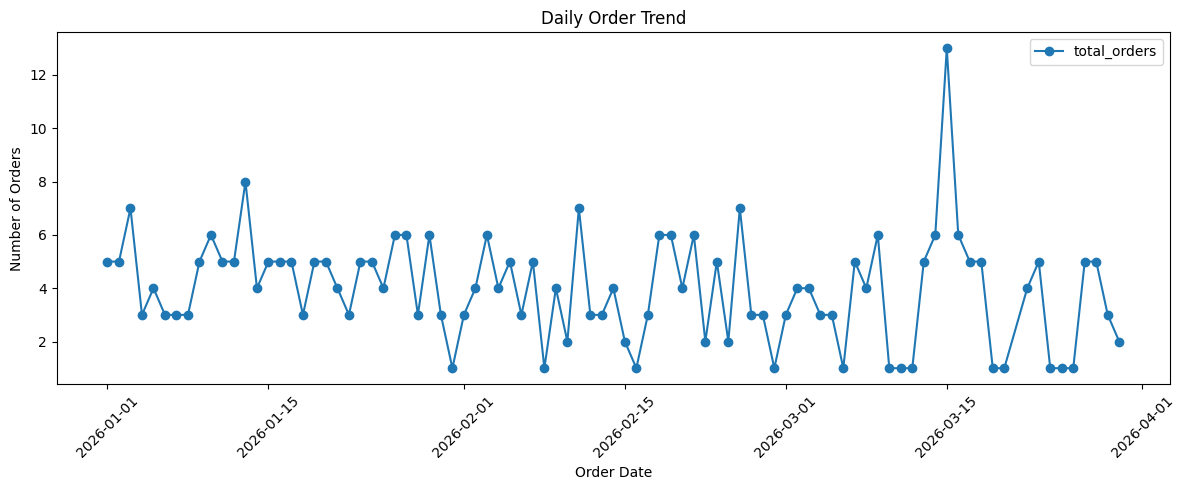

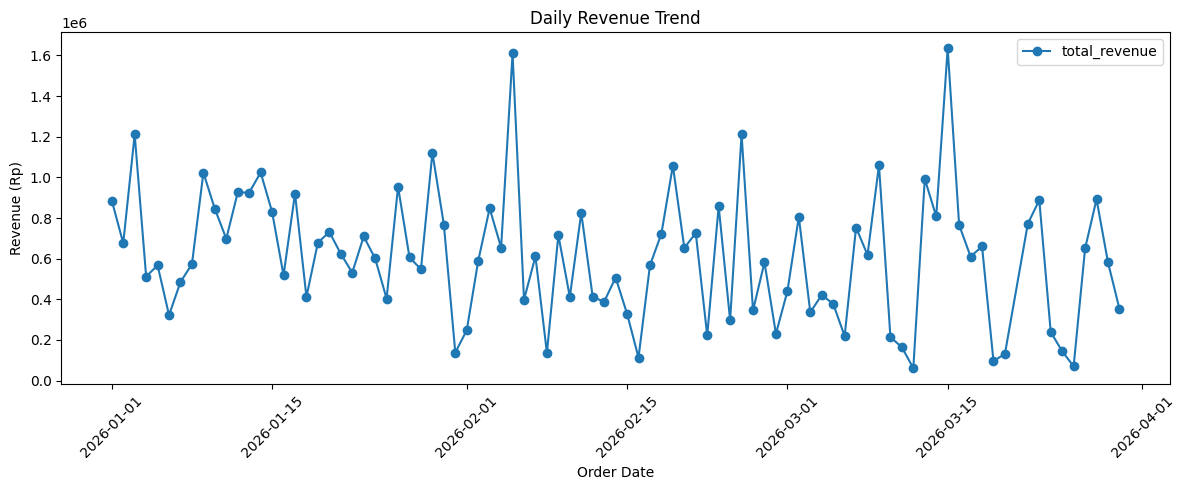

In [50]:
import matplotlib.pyplot as plt

# Ringkasan performa bisnis
print("=== BUSINESS PERFORMANCE ===")

print(f"Total Orders: {df_final_flat['order_id'].nunique():,}")

if 'total_amount' in df_final_flat.columns:
    print(f"Total Revenue: Rp{df_final_flat['total_amount'].sum():,.0f}")
    print(f"Average Order Value: Rp{df_final_flat['total_amount'].mean():,.0f}")
    print(f"Median Order Value: Rp{df_final_flat['total_amount'].median():,.0f}")

# Distribusi status order
if 'order_status' in df_final_flat.columns:
    display(df_final_flat['order_status'].value_counts())

# Tren order dan revenue per hari
if 'order_timestamp' in df_final_flat.columns:
    daily_performance = (
        df_final_flat
        .dropna(subset=['order_timestamp'])
        .assign(order_date=lambda x: x['order_timestamp'].dt.date)
        .groupby('order_date')
        .agg(
            total_orders=('order_id', 'nunique'),
            total_revenue=('total_amount', 'sum')
        )
        .reset_index()
    )

    display(daily_performance.head(10))

    daily_performance.plot(
        x='order_date',
        y='total_orders',
        kind='line',
        marker='o',
        figsize=(12, 5),
        title='Daily Order Trend'
    )
    plt.ylabel('Number of Orders')
    plt.xlabel('Order Date')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    daily_performance.plot(
        x='order_date',
        y='total_revenue',
        kind='line',
        marker='o',
        figsize=(12, 5),
        title='Daily Revenue Trend'
    )
    plt.ylabel('Revenue (Rp)')
    plt.xlabel('Order Date')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## **Restaurant performance**


In [51]:
print("=== RESTAURANT PERFORMANCE ===")

restaurant_performance = (
    df_final_flat
    .groupby(['restaurant_name', 'cuisine_type'], dropna=False)
    .agg(
        total_orders=('order_id', 'nunique'),
        total_revenue=('total_amount', 'sum'),
        avg_order_value=('total_amount', 'mean')
    )
    .reset_index()
    .sort_values('total_revenue', ascending=False)
)

display(restaurant_performance.head(10))

# Performa berdasarkan kategori makanan
cuisine_performance = (
    df_final_flat
    .groupby('cuisine_type', dropna=False)
    .agg(
        total_orders=('order_id', 'nunique'),
        total_revenue=('total_amount', 'sum')
    )
    .reset_index()
    .sort_values('total_orders', ascending=False)
)

display(cuisine_performance)

=== RESTAURANT PERFORMANCE ===


,restaurant_name,cuisine_type,total_orders,total_revenue,avg_order_value
0,SwiftBite Partner 03,Fast Food,70,11199000,159985.714286
3,SwiftBite Partner 18,Indonesian,70,10870000,155285.714286
2,SwiftBite Partner 13,Asian,70,10711000,153014.285714
4,SwiftBite Partner 23,Dessert,70,10570000,151000.000000
1,SwiftBite Partner 08,Western,70,10441000,149157.142857


,cuisine_type,total_orders,total_revenue
0,Asian,70,10711000
1,Dessert,70,10570000
2,Fast Food,70,11199000
3,Indonesian,70,10870000
4,Western,70,10441000


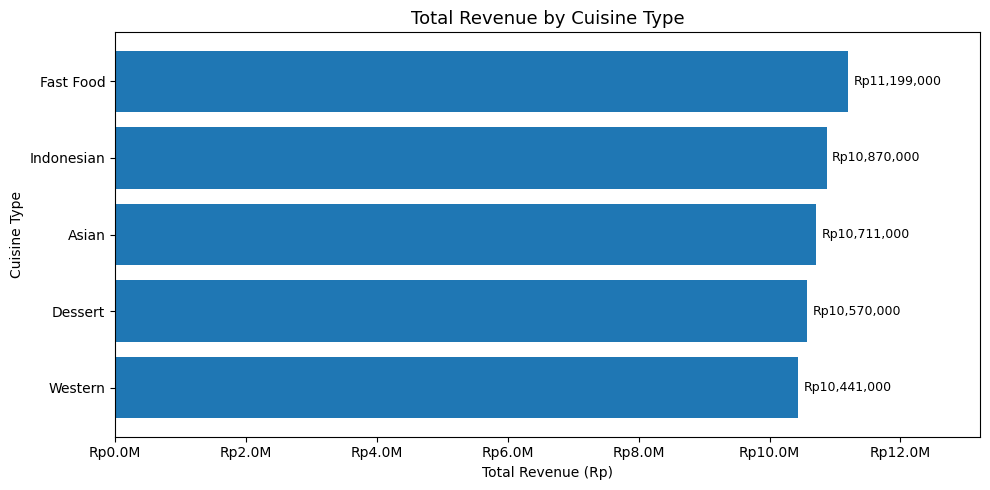

In [52]:
# Total Revenue berdasarkan Cuisine Type
cuisine_performance = (
    df_final_flat
    .groupby('cuisine_type', dropna=False)
    .agg(
        total_revenue=('total_amount', 'sum')
    )
    .reset_index()
    .sort_values('total_revenue', ascending=True)
)

# Visualisasi
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    cuisine_performance['cuisine_type'].astype(str),
    cuisine_performance['total_revenue']
)

# Label nilai revenue
ax.bar_label(
    bars,
    labels=[
        f'Rp{x:,.0f}'
        for x in cuisine_performance['total_revenue']
    ],
    padding=4,
    fontsize=9
)

ax.set_title('Total Revenue by Cuisine Type', fontsize=13)
ax.set_xlabel('Total Revenue (Rp)')
ax.set_ylabel('Cuisine Type')

ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f'Rp{x/1_000_000:.1f}M')
)

ax.set_xlim(0, cuisine_performance['total_revenue'].max() * 1.18)

plt.tight_layout()
plt.show()


## **Customer analysis**


In [53]:

print("=== CUSTOMER ANALYSIS ===")

# Performa berdasarkan segmen pelanggan
if 'customer_segment' in df_final_flat.columns:
    customer_segment_analysis = (
        df_final_flat
        .groupby('customer_segment', dropna=False)
        .agg(
            total_orders=('order_id', 'nunique'),
            total_revenue=('total_amount', 'sum'),
            avg_order_value=('total_amount', 'mean')
        )
        .reset_index()
        .sort_values('total_orders', ascending=False)
    )

    display(customer_segment_analysis)

# Distribusi berdasarkan zona pelanggan
if 'customer_zone' in df_final_flat.columns:
    customer_zone_analysis = (
        df_final_flat
        .groupby('customer_zone', dropna=False)
        .agg(
            total_orders=('order_id', 'nunique'),
            total_revenue=('total_amount', 'sum')
        )
        .reset_index()
        .sort_values('total_orders', ascending=False)
    )

    display(customer_zone_analysis)


=== CUSTOMER ANALYSIS ===


,customer_segment,total_orders,total_revenue,avg_order_value
2,Regular,118,17299000,146601.694915
0,Loyal,117,18483000,157974.358974
1,New,115,18009000,156600.000000


,customer_zone,total_orders,total_revenue
4,West,131,20083000
2,North,88,13247000
3,South,58,9646000
1,East,44,6775000
0,Central,29,4040000


## **Delivery performance**


In [54]:

print("=== DELIVERY PERFORMANCE ===")

# 1. Distribusi status pengiriman
print("\n1. Delivery Status Distribution")

delivery_status = (
    df_final_flat['delivery_status']
    .value_counts(dropna=False)
    .rename_axis('delivery_status')
    .reset_index(name='total_orders')
)

delivery_status['percentage'] = (
    delivery_status['total_orders'] /
    len(df_final_flat) * 100
).round(2)

display(delivery_status)


# 2. Statistik jarak pengiriman
print("\n2. Delivery Distance Statistics")

display(
    df_final_flat['distance_km']
    .describe()
    .to_frame('distance_km')
    .round(2)
)


# 3. Statistik estimasi waktu pengiriman
print("\n3. Promised Delivery Time Statistics")

display(
    df_final_flat['promised_delivery_minutes']
    .describe()
    .to_frame('promised_delivery_minutes')
    .round(2)
)


# 4. Performa pengiriman berdasarkan status
print("\n4. Delivery Performance by Status")

delivery_analysis = (
    df_final_flat
    .groupby('delivery_status', dropna=False)
    .agg(
        total_orders=('order_id', 'nunique'),
        avg_distance_km=('distance_km', 'mean'),
        avg_promised_minutes=('promised_delivery_minutes', 'mean')
    )
    .reset_index()
    .round(2)
)

display(delivery_analysis)


# 5. Rata-rata estimasi waktu berdasarkan jarak
print("\n5. Estimated Delivery Time by Distance")

df_final_flat['distance_category'] = pd.cut(
    df_final_flat['distance_km'],
    bins=[0, 2, 5, 10, float('inf')],
    labels=['0-2 km', '2-5 km', '5-10 km', '>10 km'],
    include_lowest=True
)

distance_analysis = (
    df_final_flat
    .groupby('distance_category', observed=False)
    .agg(
        total_orders=('order_id', 'nunique'),
        avg_promised_minutes=('promised_delivery_minutes', 'mean')
    )
    .reset_index()
    .round(2)
)

display(distance_analysis)


=== DELIVERY PERFORMANCE ===

1. Delivery Status Distribution


,delivery_status,total_orders,percentage
0,delivered,318,90.86
1,cancelled,16,4.57
2,NaN,16,4.57



2. Delivery Distance Statistics


,distance_km
count,334.00
mean,8.09
std,4.16
min,0.90
25%,4.65
50%,7.95
75%,11.90
max,18.20



3. Promised Delivery Time Statistics


,promised_delivery_minutes
count,334.00
mean,45.49
std,8.72
min,30.00
25%,38.00
50%,45.00
75%,53.00
max,60.00



4. Delivery Performance by Status


,delivery_status,total_orders,avg_distance_km,avg_promised_minutes
0,cancelled,16,6.37,45.19
1,delivered,318,8.18,45.51
2,NaN,16,NaN,NaN



5. Estimated Delivery Time by Distance


,distance_category,total_orders,avg_promised_minutes
0,0-2 km,28,44.04
1,2-5 km,68,46.47
2,5-10 km,124,45.66
3,>10 km,114,45.09


In [55]:

print("=== DELIVERY PERFORMANCE ===")

# Menghitung durasi aktual pengiriman dalam menit
df_final_flat['actual_delivery_minutes'] = (
    df_final_flat['delivered_at'] -
    df_final_flat['picked_up_at']
).dt.total_seconds() / 60

# Menghitung selisih durasi aktual dengan estimasi
df_final_flat['delay_minutes'] = (
    df_final_flat['actual_delivery_minutes'] -
    df_final_flat['promised_delivery_minutes']
)

# Menentukan keterlambatan
df_final_flat['is_late'] = (
    df_final_flat['delay_minutes'] > 0
).astype(bool)

# Order yang belum memiliki durasi aktual tidak dimasukkan
# dalam analisis ketepatan waktu
df_final_flat.loc[
    df_final_flat['actual_delivery_minutes'].isna(),
    'is_late'
] = False

# 1. Statistik durasi aktual
print("\n1. Actual Delivery Duration")

display(
    df_final_flat['actual_delivery_minutes']
    .describe()
    .to_frame('actual_delivery_minutes')
    .round(2)
)

# 2. Statistik keterlambatan
print("\n2. Delivery Delay Statistics")

display(
    df_final_flat['delay_minutes']
    .describe()
    .to_frame('delay_minutes')
    .round(2)
)

# 3. Distribusi ketepatan waktu
print("\n3. Delivery Timeliness")

timeliness = (
    df_final_flat['is_late']
    .value_counts()
    .rename_axis('is_late')
    .reset_index(name='total_orders')
)

display(timeliness)

# 4. Perbandingan aktual dan estimasi
print("\n4. Actual vs Promised Delivery Time")

display(
    df_final_flat[
        [
            'order_id',
            'promised_delivery_minutes',
            'actual_delivery_minutes',
            'delay_minutes',
            'is_late'
        ]
    ].head(10)
)

# 5. Memastikan tipe data Boolean
print("\nTipe data is_late:", df_final_flat['is_late'].dtype)


=== DELIVERY PERFORMANCE ===

1. Actual Delivery Duration


,actual_delivery_minutes
count,318.00
mean,29.23
std,15.13
min,5.00
25%,17.25
50%,26.50
75%,39.75
max,81.00



2. Delivery Delay Statistics


,delay_minutes
count,318.00
mean,-16.28
std,12.12
min,-37.00
25%,-25.00
50%,-19.00
75%,-10.00
max,32.00



3. Delivery Timeliness


,is_late,total_orders
0,False,312
1,True,38



4. Actual vs Promised Delivery Time


,order_id,promised_delivery_minutes,actual_delivery_minutes,delay_minutes,is_late
0,O00001,48.0,35.0,-13.0,False
1,O00002,36.0,46.0,10.0,True
2,O00003,30.0,5.0,-25.0,False
3,O00004,36.0,30.0,-6.0,False
4,O00005,44.0,11.0,-33.0,False
5,O00006,44.0,26.0,-18.0,False
6,O00007,45.0,24.0,-21.0,False
7,O00008,54.0,22.0,-32.0,False
8,O00009,33.0,5.0,-28.0,False
9,O00010,54.0,46.0,-8.0,False



Tipe data is_late: bool


## **Payment analysis**


In [56]:

print("=== PAYMENT ANALYSIS ===")

# 1. Distribusi metode pembayaran
print("\n1. Payment Method Distribution")

payment_method_analysis = (
    df_final_flat
    .groupby('payment_method', dropna=False)
    .agg(
        total_orders=('order_id', 'nunique'),
        total_payment=('payment_amount', 'sum')
    )
    .reset_index()
    .sort_values('total_orders', ascending=False)
)

display(payment_method_analysis)


# 2. Distribusi status pembayaran
print("\n2. Payment Status Distribution")

payment_status_analysis = (
    df_final_flat['payment_status']
    .value_counts(dropna=False)
    .rename_axis('payment_status')
    .reset_index(name='total_orders')
)

payment_status_analysis['percentage'] = (
    payment_status_analysis['total_orders'] /
    df_final_flat['order_id'].nunique() * 100
).round(2)

display(payment_status_analysis)


# 3. Statistik nominal pembayaran
print("\n3. Payment Amount Statistics")

display(
    df_final_flat['payment_amount']
    .describe()
    .to_frame('payment_amount')
    .round(2)
)


# 4. Perbandingan nominal pembayaran dengan total order
print("\n4. Payment vs Order Amount")

df_final_flat['payment_difference'] = (
    df_final_flat['payment_amount'] -
    df_final_flat['total_amount']
)

display(
    df_final_flat[
        ['order_id', 'total_amount', 'payment_amount',
         'payment_difference', 'payment_status']
    ].head(10)
)


# 5. Jumlah percobaan pembayaran
print("\n5. Payment Attempt Analysis")

attempt_analysis = (
    df_final_flat
    .groupby('attempt_number', dropna=False)
    .agg(
        total_orders=('order_id', 'nunique'),
        total_payment=('payment_amount', 'sum')
    )
    .reset_index()
    .sort_values('attempt_number')
)

display(attempt_analysis)


=== PAYMENT ANALYSIS ===

1. Payment Method Distribution


,payment_method,total_orders,total_payment
0,bank_transfer,88,13110000
3,e_wallet,88,13113000
1,cash,87,13469000
2,credit_card,87,14089000



2. Payment Status Distribution


,payment_status,total_orders,percentage
0,successful,318,90.86
1,failed,21,6.00
2,refunded,11,3.14



3. Payment Amount Statistics


,payment_amount
count,350.0
mean,153660.0
std,86430.8
min,7000.0
25%,99000.0
50%,143500.0
75%,195000.0
max,1098000.0



4. Payment vs Order Amount


,order_id,total_amount,payment_amount,payment_difference,payment_status
0,O00001,62000,62000,0,successful
1,O00002,133000,133000,0,successful
2,O00003,233000,233000,0,successful
3,O00004,76000,76000,0,successful
4,O00005,120000,120000,0,successful
5,O00006,244000,244000,0,successful
6,O00007,123000,123000,0,successful
7,O00008,116000,116000,0,successful
8,O00009,220000,220000,0,successful
9,O00010,158000,158000,0,successful



5. Payment Attempt Analysis


,attempt_number,total_orders,total_payment
0,1,319,49621000
1,2,31,4160000


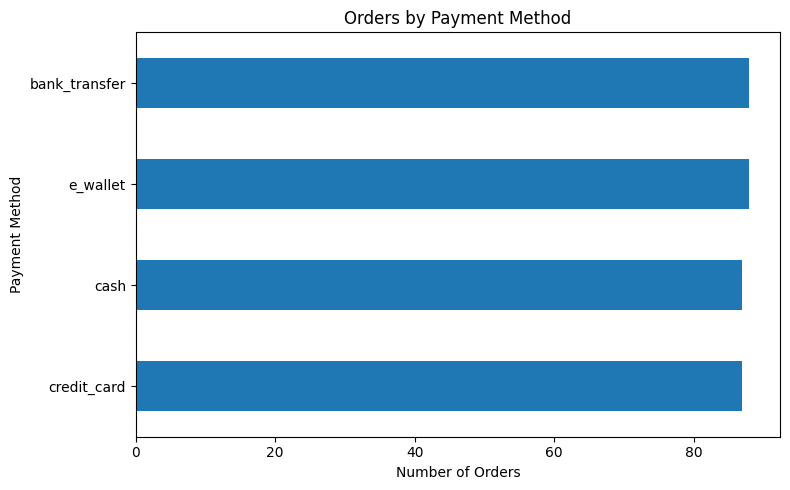

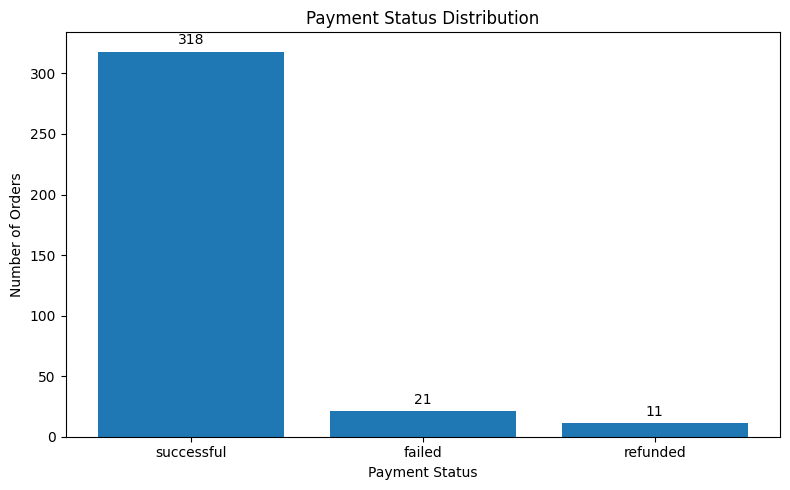

In [57]:

# Grafik metode pembayaran
fig, ax = plt.subplots(figsize=(8, 5))

payment_method_analysis.sort_values(
    'total_orders'
).plot(
    x='payment_method',
    y='total_orders',
    kind='barh',
    ax=ax,
    legend=False
)

ax.set_title('Orders by Payment Method')
ax.set_xlabel('Number of Orders')
ax.set_ylabel('Payment Method')

plt.tight_layout()
plt.show()


# Grafik status pembayaran
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    payment_status_analysis['payment_status'].astype(str),
    payment_status_analysis['total_orders']
)

ax.bar_label(bars, padding=3)
ax.set_title('Payment Status Distribution')
ax.set_xlabel('Payment Status')
ax.set_ylabel('Number of Orders')

plt.tight_layout()
plt.show()


## **Customer Satisfaction**


In [58]:

print("=== CUSTOMER SATISFACTION ===")

# 1. Distribusi rating
print("\n1. Customer Rating Distribution")

rating_analysis = (
    df_final_flat['rating_label']
    .value_counts(dropna=False)
    .rename_axis('rating_label')
    .reset_index(name='total_orders')
)

display(rating_analysis)


# 2. Statistik rating numerik
print("\n2. Rating Statistics")

display(
    df_final_flat['rating']
    .describe()
    .to_frame('rating')
    .round(2)
)


# 3. Status ketersediaan review
print("\n3. Review Availability")

display(
    df_final_flat['review_status']
    .value_counts(dropna=False)
    .rename_axis('review_status')
    .reset_index(name='total_orders')
)


# 4. Status ketersediaan teks ulasan
print("\n4. Review Text Availability")

display(
    df_final_flat['review_text_status']
    .value_counts(dropna=False)
    .rename_axis('review_text_status')
    .reset_index(name='total_orders')
)


# 5. Rata-rata rating berdasarkan zona restoran
print("\n5. Average Rating by Restaurant Zone")

rating_by_zone = (
    df_final_flat
    .groupby('restaurant_zone', dropna=False)
    .agg(
        total_ratings=('rating', 'count'),
        average_rating=('rating', 'mean')
    )
    .reset_index()
    .sort_values('average_rating', ascending=False)
)

display(rating_by_zone.round(2))


=== CUSTOMER SATISFACTION ===

1. Customer Rating Distribution


,rating_label,total_orders
0,No Rating,146
1,4 - Satisfied,72
2,5 - Very Satisfied,54
3,3 - Neutral,41
4,2 - Dissatisfied,24
5,1 - Very Dissatisfied,13



2. Rating Statistics


,rating
count,204.00
mean,3.64
std,1.18
min,1.00
25%,3.00
50%,4.00
75%,5.00
max,5.00



3. Review Availability


,review_status,total_orders
0,Review Available,204
1,No Review,146



4. Review Text Availability


,review_text_status,total_orders
0,Text Available,193
1,No Review,146
2,No Text,11



5. Average Rating by Restaurant Zone


,restaurant_zone,total_ratings,average_rating
0,Central,43,3.70
2,South,81,3.63
1,East,80,3.61


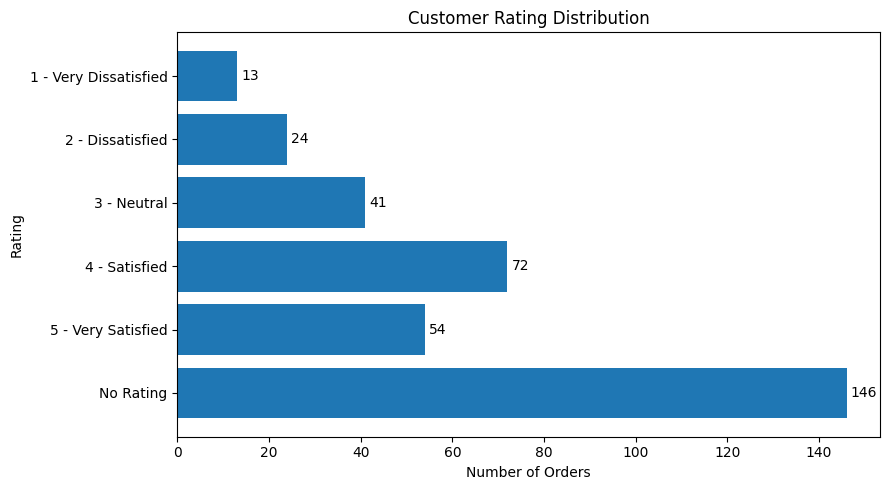

In [59]:

# Grafik distribusi rating
rating_order = [
    '1 - Very Dissatisfied',
    '2 - Dissatisfied',
    '3 - Neutral',
    '4 - Satisfied',
    '5 - Very Satisfied',
    'No Rating'
]

rating_counts = (
    df_final_flat['rating_label']
    .value_counts()
    .reindex(rating_order, fill_value=0)
)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    rating_counts.index[::-1],
    rating_counts.values[::-1]
)

ax.bar_label(bars, padding=3)
ax.set_title('Customer Rating Distribution')
ax.set_xlabel('Number of Orders')
ax.set_ylabel('Rating')

plt.tight_layout()
plt.show()


## **Customer and Restaurant Zone Analysis**


In [60]:

print("=== ZONE ANALYSIS ===")

zone_analysis = (
    df_final_flat
    .groupby(
        ['customer_zone', 'restaurant_zone'],
        dropna=False
    )
    .agg(
        total_orders=('order_id', 'nunique'),
        total_revenue=('total_amount', 'sum'),
        average_order_value=('total_amount', 'mean')
    )
    .reset_index()
    .sort_values('total_orders', ascending=False)
)

display(zone_analysis.head(20))


=== ZONE ANALYSIS ===


,customer_zone,restaurant_zone,total_orders,total_revenue,average_order_value
14,West,South,53,8549000,161301.886792
13,West,East,52,6992000,134461.538462
8,North,South,36,5487000,152416.666667
7,North,East,35,5263000,150371.428571
12,West,Central,26,4542000,174692.307692
10,South,East,24,4366000,181916.666667
11,South,South,22,3737000,169863.636364
4,East,East,18,3086000,171444.444444
5,East,South,17,2358000,138705.882353
6,North,Central,17,2497000,146882.352941


## **Promo Code Analysis**


In [61]:

print("=== PROMO CODE ANALYSIS ===")

promo_analysis = (
    df_final_flat
    .assign(
        promo_usage=np.where(
            df_final_flat['promo_code'].notna(),
            'With Promo',
            'Without Promo'
        )
    )
    .groupby('promo_usage')
    .agg(
        total_orders=('order_id', 'nunique'),
        total_revenue=('total_amount', 'sum'),
        average_order_value=('total_amount', 'mean'),
        average_discount=('discount_amount', 'mean')
    )
    .reset_index()
)

display(promo_analysis.round(2))


=== PROMO CODE ANALYSIS ===


,promo_usage,total_orders,total_revenue,average_order_value,average_discount
0,With Promo,161,29189000,181298.14,6552.80
1,Without Promo,189,24602000,130169.31,5476.19


In [62]:
import os

# Menentukan lokasi dan nama file untuk ekspor
export_file_path = os.path.join(folder_path, 'swiftbite_final_cleaned.csv')

# Mengekspor DataFrame ke CSV
df_final_flat.to_csv(export_file_path, index=False)

print(f"[SUKSES] Berhasil mengekspor df_final_flat ({df_final_flat.shape[0]} baris) ke:")
print(export_file_path)

[SUKSES] Berhasil mengekspor df_final_flat (350 baris) ke:
/content/drive/My Drive/SB-P12/swiftbite_final_cleaned.csv


# **Pertanyaan Bisnis**

## **A. Kinerja Pesanan**

1. Bagaimana perkembangan jumlah pesanan dan nilai transaksi selama periode analisis?

In [63]:
# Distribusi status pesanan
order_status = df_final_flat['order_status'].value_counts(dropna=False)

print(order_status)
print("\nPersentase:")
print(df_final_flat['order_status'].value_counts(
    normalize=True, dropna=False
).mul(100).round(2))

# Ringkasan nilai transaksi
df_final_flat.groupby('order_status')['total_amount'].agg(
    jumlah_pesanan='count',
    total_transaksi='sum',
    rata_rata_transaksi='mean',
    median_transaksi='median'
).round(2)

order_status
completed    318
cancelled     32
Name: count, dtype: int64

Persentase:
order_status
completed    90.86
cancelled     9.14
Name: proportion, dtype: float64


,jumlah_pesanan,total_transaksi,rata_rata_transaksi,median_transaksi
order_status,,,,
cancelled,32,4360000,136250.0,134500.0
completed,318,49431000,155443.4,148000.0


/tmp/ipykernel_2712/1847847524.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


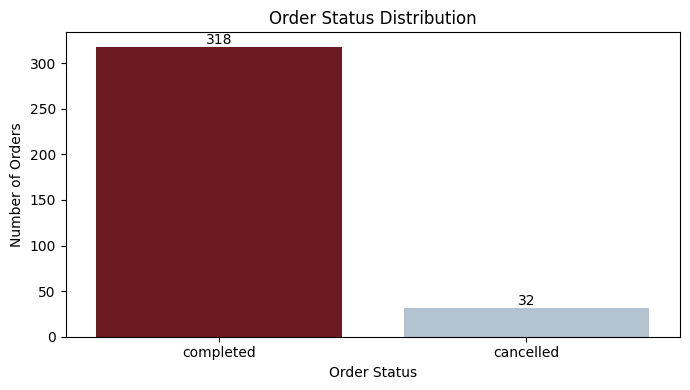

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))

custom_colors = {'completed': '#790D16', 'cancelled': '#AEC4D4'}

sns.countplot(
    data=df_final_flat,
    x='order_status',
    order=['completed', 'cancelled'],
    palette=custom_colors  # Menerapkan warna kustom di sini
)

plt.title('Order Status Distribution')
plt.xlabel('Order Status')
plt.ylabel('Number of Orders')

for container in plt.gca().containers:
    plt.bar_label(container)

plt.tight_layout()
plt.show()

/tmp/ipykernel_2712/3811972114.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


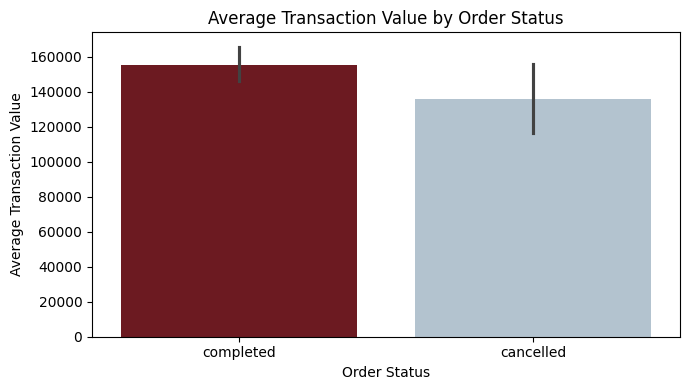

In [65]:
plt.figure(figsize=(7, 4))

custom_colors = {'completed': '#790D16', 'cancelled': '#AEC4D4'}

sns.barplot(
    data=df_final_flat,
    x='order_status',
    y='total_amount',
    order=['completed', 'cancelled'],
    estimator='mean',
    palette=custom_colors
)

plt.title('Average Transaction Value by Order Status')
plt.xlabel('Order Status')
plt.ylabel('Average Transaction Value')

plt.tight_layout()
plt.show()

Pertanyaan bisnis
Bagaimana performa penyelesaian pesanan dan nilai transaksi SwiftBite?
- 90,86% pesanan berhasil diselesaikan, sedangkan 9,14% dibatalkan.
- Rata-rata nilai transaksi pesanan completed sebesar Rp155.443, lebih tinggi dibandingkan cancelled sebesar Rp136.250

Kesimpulan sementara
Mayoritas pesanan SwiftBite berhasil diselesaikan. Pesanan completed juga memiliki rata-rata nilai transaksi lebih tinggi dibandingkan pesanan cancelled.

2. Bagaimana perkembangan jumlah pesanan dan nilai transaksi selama periode analisis?

In [67]:
# Pastikan kolom timestamp bertipe datetime
df_final_flat['order_timestamp'] = pd.to_datetime(
    df_final_flat['order_timestamp']
)

# Ekstraksi periode
df_final_flat['order_date'] = df_final_flat['order_timestamp'].dt.date
df_final_flat['order_day'] = df_final_flat['order_timestamp'].dt.day_name()
df_final_flat['order_hour'] = df_final_flat['order_timestamp'].dt.hour
df_final_flat['order_month'] = df_final_flat['order_timestamp'].dt.to_period('M')

# Tren jumlah pesanan harian
daily_orders = df_final_flat.groupby('order_date')['order_id'].nunique()

# Tren transaksi bulanan
monthly_orders = df_final_flat.groupby('order_month').agg(
    jumlah_pesanan=('order_id', 'nunique'),
    total_transaksi=('total_amount', 'sum')
)

print(monthly_orders)

# Pola pesanan berdasarkan hari
print(df_final_flat.groupby('order_day')['order_id'].nunique())

# Pola pesanan berdasarkan jam
print(df_final_flat.groupby('order_hour')['order_id'].nunique().sort_values(
    ascending=False
))

             jumlah_pesanan  total_transaksi
order_month                                 
2026-01                 140         21766000
2026-02                 105         16268000
2026-03                 105         15757000
order_day
Friday       48
Monday       57
Saturday     56
Sunday       50
Thursday     45
Tuesday      46
Wednesday    48
Name: order_id, dtype: int64
order_hour
20    24
9     20
2     19
6     19
8     18
12    17
3     17
16    16
15    16
21    16
1     15
11    15
18    14
17    13
4     13
0     13
23    12
7     12
5     11
13    11
22    11
14    11
10    10
19     7
Name: order_id, dtype: int64


In [68]:
# Ringkasan pesanan bulanan
monthly_summary = df_final_flat.groupby('order_month').agg(
    jumlah_pesanan=('order_id', 'nunique'),
    total_transaksi=('total_amount', 'sum')
).reset_index()

monthly_summary['order_month'] = monthly_summary['order_month'].astype(str)

display(monthly_summary)

# Ringkasan pesanan berdasarkan hari
day_order = [
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
]

daily_summary = (
    df_final_flat.groupby('order_day')['order_id']
    .nunique()
    .reindex(day_order)
    .reset_index()
)

daily_summary.columns = ['hari', 'jumlah_pesanan']

display(daily_summary)

# Ringkasan pesanan berdasarkan jam
hourly_summary = (
    df_final_flat.groupby('order_hour')['order_id']
    .nunique()
    .reset_index()
)

hourly_summary.columns = ['jam', 'jumlah_pesanan']

display(hourly_summary)

,order_month,jumlah_pesanan,total_transaksi
0,2026-01,140,21766000
1,2026-02,105,16268000
2,2026-03,105,15757000


,hari,jumlah_pesanan
0,Monday,57
1,Tuesday,46
2,Wednesday,48
3,Thursday,45
4,Friday,48
5,Saturday,56
6,Sunday,50


,jam,jumlah_pesanan
0,0,13
1,1,15
2,2,19
3,3,17
4,4,13
5,5,11
6,6,19
7,7,12
8,8,18
9,9,20


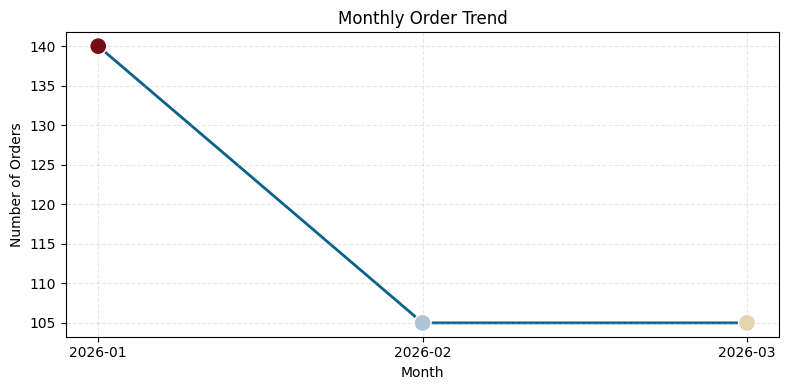

In [76]:
plt.figure(figsize=(8, 4))
custom_colors = {'2026-01': '#790D16', '2026-02': '#AEC4D4', '2026-03': '#E5D3AF'}


sns.lineplot(
    data=monthly_summary,
    x='order_month',
    y='jumlah_pesanan',
    color='#086288',
    linewidth=2,
    zorder=1
)


sns.scatterplot(
    data=monthly_summary,
    x='order_month',
    y='jumlah_pesanan',
    hue='order_month',
    palette=custom_colors,
    s=150,  # Ukuran titik agar terlihat jelas
    legend=False,
    zorder=2
)

plt.title('Monthly Order Trend')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

/tmp/ipykernel_2712/2432649114.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


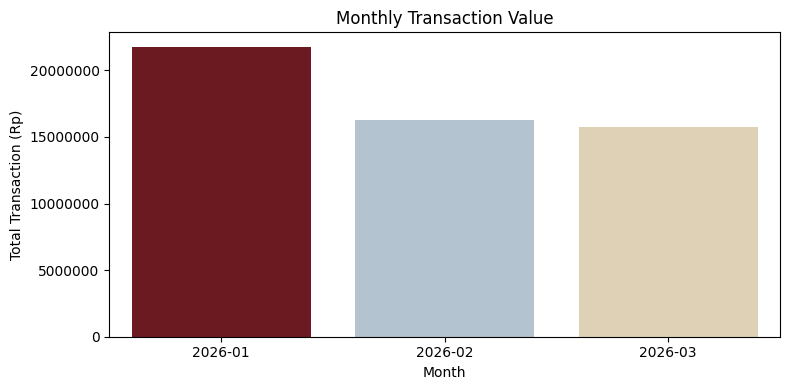

In [72]:
plt.figure(figsize=(8, 4))

custom_colors = {'2026-01': '#790D16', '2026-02': '#AEC4D4', '2026-03': '#E5D3AF'}
sns.barplot(
    data=monthly_summary,
    x='order_month',
    y='total_transaksi',
    palette=custom_colors
)

plt.title('Monthly Transaction Value')
plt.xlabel('Month')
plt.ylabel('Total Transaction (Rp)')
plt.ticklabel_format(axis='y', style='plain')
plt.tight_layout()
plt.show()

Januari mencatat jumlah pesanan dan total transaksi tertinggi.



Jumlah pesanan turun sekitar 25% pada Februari dibandingkan Januari.



Pada Maret, jumlah pesanan tetap, tetapi total transaksi kembali menurun.

/tmp/ipykernel_2712/1574097973.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


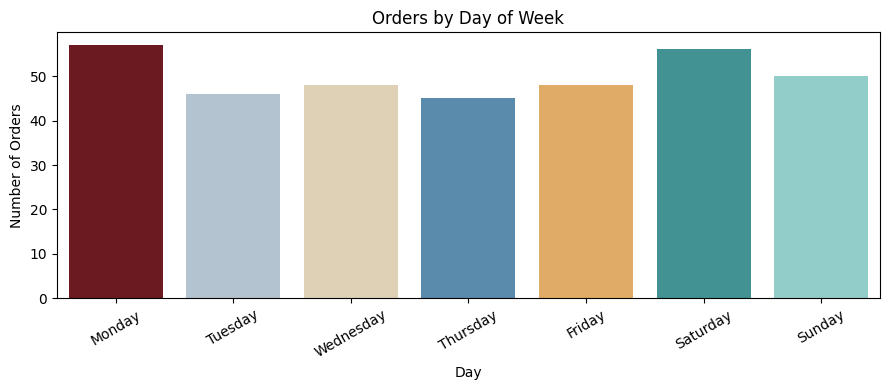

In [85]:
plt.figure(figsize=(9, 4))
custom_colors = {'Monday': '#790D16', 'Tuesday': '#AEC4D4', 'Wednesday': '#E5D3AF', 'Thursday': '#4D8DBA',
                 'Friday': '#F4AE52', 'Saturday': '#359FA0', 'Sunday': '#8AD6D1'}
sns.barplot(
    data=daily_summary,
    x='hari',
    y='jumlah_pesanan',
    palette=custom_colors
)

plt.title('Orders by Day of Week')
plt.xlabel('Day')
plt.ylabel('Number of Orders')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

- Senin menjadi hari dengan jumlah pesanan tertinggi (57).
- Sabtu berada di posisi kedua (56).
- Kamis mencatat jumlah pesanan terendah (45).

/tmp/ipykernel_2712/780893062.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


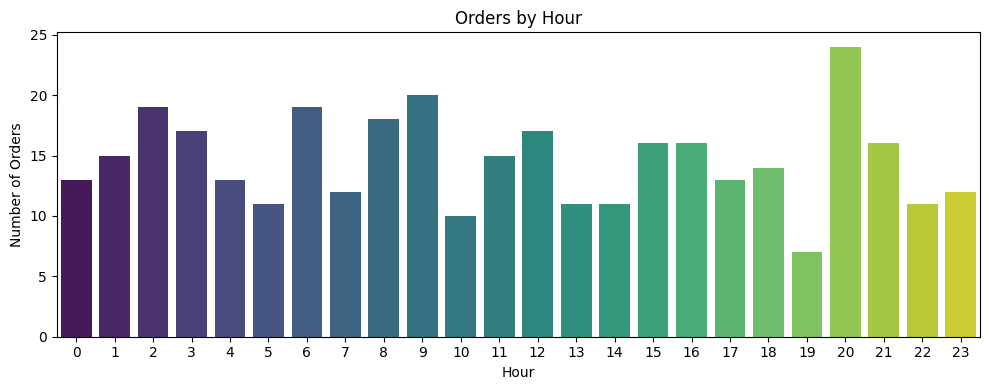

In [86]:
plt.figure(figsize=(10, 4))

sns.barplot(
    data=hourly_summary,
    x='jam',
    y='jumlah_pesanan',
    palette='viridis'
)

plt.title('Orders by Hour')
plt.xlabel('Hour')
plt.ylabel('Number of Orders')
plt.xticks(range(24))
plt.tight_layout()
plt.show()

- Pukul 20.00 mencatat jumlah pesanan tertinggi, yaitu 24 pesanan.
- Pukul 09.00 berada di urutan kedua dengan 20 pesanan.
- Pukul 19.00 mencatat jumlah pesanan terendah, yaitu 7 pesanan.

In [87]:
restaurant_analysis = df_final_flat.groupby('restaurant_id').agg(
    jumlah_pesanan=('order_id', 'nunique'),
    total_transaksi=('total_amount', 'sum'),
    rata_rata_transaksi=('total_amount', 'mean'),
    rata_rata_rating=('rating', 'mean')
).round(2)

restaurant_analysis.sort_values(
    'total_transaksi', ascending=False
)

,jumlah_pesanan,total_transaksi,rata_rata_transaksi,rata_rata_rating
restaurant_id,,,,
R0003,70,11199000,159985.71,3.54
R0018,70,10870000,155285.71,3.58
R0013,70,10711000,153014.29,3.70
R0023,70,10570000,151000.00,3.72
R0008,70,10441000,149157.14,3.65


In [88]:
# Distribusi rating
print(df_final_flat['rating'].value_counts(dropna=False).sort_index())

# Rata-rata rating
print("Rata-rata rating:", df_final_flat['rating'].mean())

# Perbandingan rating berdasarkan status pesanan
print(
    df_final_flat.groupby('order_status')['rating']
    .agg(['count', 'mean', 'median'])
    .round(2)
)

# Persentase pesanan yang memiliki review
print(
    df_final_flat['has_review']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

rating
1.0     13
2.0     24
3.0     41
4.0     72
5.0     54
NaN    146
Name: count, dtype: int64
Rata-rata rating: 3.6372549019607843
              count  mean  median
order_status                     
cancelled         0   NaN     NaN
completed       204  3.64     4.0
has_review
True     58.29
False    41.71
Name: proportion, dtype: float64


/tmp/ipykernel_2712/1089774259.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


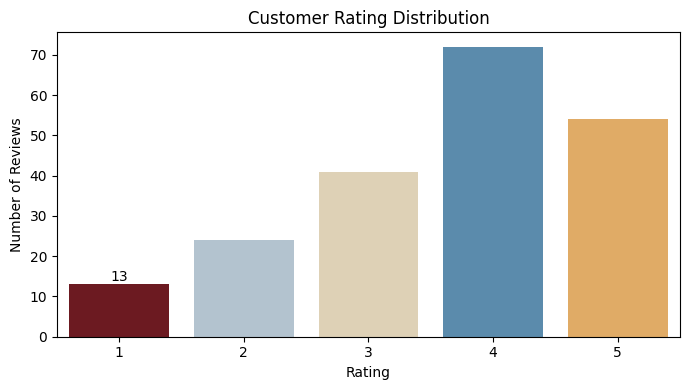

In [91]:
rating_summary = (
    df_final_flat['rating']
    .value_counts()
    .reindex([1, 2, 3, 4, 5], fill_value=0)
    .rename_axis('rating')
    .reset_index(name='jumlah_review')
)

plt.figure(figsize=(7, 4))
custom_colors = {'1': '#790D16', '2': '#AEC4D4', '3': '#E5D3AF', '4': '#4D8DBA',
                 '5': '#F4AE52'}
ax = sns.barplot(
    data=rating_summary,
    x='rating',
    y='jumlah_review',
    palette=custom_colors
)

ax.bar_label(ax.containers[0])

plt.title('Customer Rating Distribution')
plt.xlabel('Rating')
plt.ylabel('Number of Reviews')
plt.xticks([0, 1, 2, 3, 4], [1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()

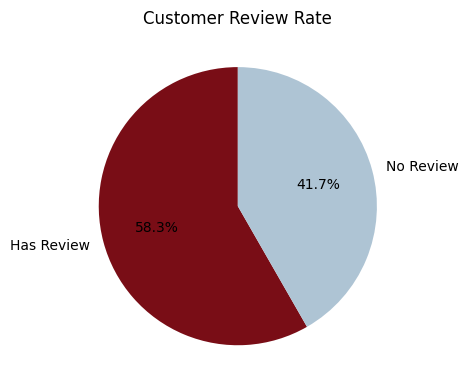

In [94]:
review_summary = (
    df_final_flat['has_review']
    .value_counts()
    .rename(index={True: 'Has Review', False: 'No Review'})
    .reset_index()
)

review_summary.columns = ['review_status', 'jumlah_pesanan']

plt.figure(figsize=(6, 4))
# Menyiapkan list warna kustom yang dipetakan berdasarkan status pada DataFrame
color_map = {'Has Review': '#790D16', 'No Review': '#AEC4D4'}
custom_colors = [color_map[status] for status in review_summary['review_status']]

plt.pie(
    review_summary['jumlah_pesanan'],
    labels=review_summary['review_status'],
    autopct='%1.1f%%',
    startangle=90,
    colors=custom_colors  # Menggunakan parameter 'colors' sebagai ganti 'palette'
)

plt.title('Customer Review Rate')
plt.tight_layout()
plt.show()

Kesimpulan sementara
Mayoritas pelanggan memberikan rating positif (4–5), dengan rata-rata rating 3,64. Namun, baru 58,29% pesanan yang memiliki review, sehingga penilaian pengalaman pelanggan belum mencakup seluruh pesanan.

In [95]:
# Kelompokkan pesanan berdasarkan penggunaan promo
df_final_flat['promo_usage'] = df_final_flat['promo_code'].notna()

promo_analysis = df_final_flat.groupby('promo_usage').agg(
    jumlah_pesanan=('order_id', 'nunique'),
    rata_rata_transaksi=('total_amount', 'mean'),
    total_transaksi=('total_amount', 'sum')
).round(2)

print(promo_analysis)

             jumlah_pesanan  rata_rata_transaksi  total_transaksi
promo_usage                                                      
False                   189            130169.31         24602000
True                    161            181298.14         29189000


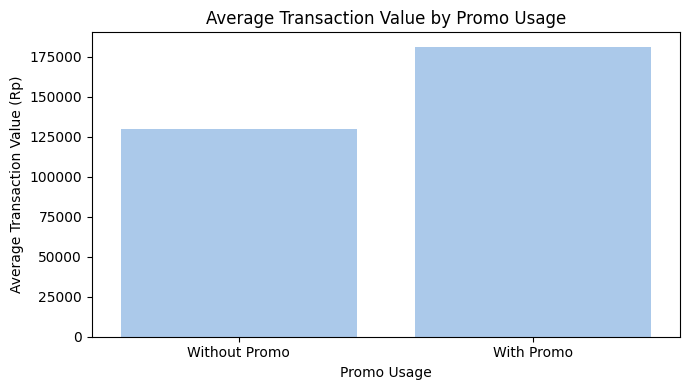

In [96]:
plt.figure(figsize=(7, 4))

ax = sns.barplot(
    data=promo_analysis.reset_index(),
    x='promo_usage',
    y='rata_rata_transaksi'
)

ax.set_xticks([0, 1])
ax.set_xticklabels(['Without Promo', 'With Promo'])

plt.title('Average Transaction Value by Promo Usage')
plt.xlabel('Promo Usage')
plt.ylabel('Average Transaction Value (Rp)')
plt.ticklabel_format(axis='y', style='plain')

plt.tight_layout()
plt.show()

Interpretasi:
- Pesanan dengan promo memiliki rata-rata transaksi sebesar Rp181.298, lebih tinggi dibandingkan tanpa promo sebesar Rp130.169.
- Terdapat selisih rata-rata transaksi sekitar Rp51.129 (39,3%).
- Meskipun jumlah pesanan dengan promo lebih sedikit, total transaksinya justru lebih tinggi.
Kesimpulan sementara
Pesanan yang menggunakan promo menunjukkan nilai transaksi rata-rata lebih tinggi dibandingkan pesanan tanpa promo. Hal ini mengindikasikan adanya hubungan antara penggunaan promo dan nilai transaksi pelanggan.

Namun, hasil ini belum membuktikan bahwa promo menyebabkan peningkatan nilai transaksi.

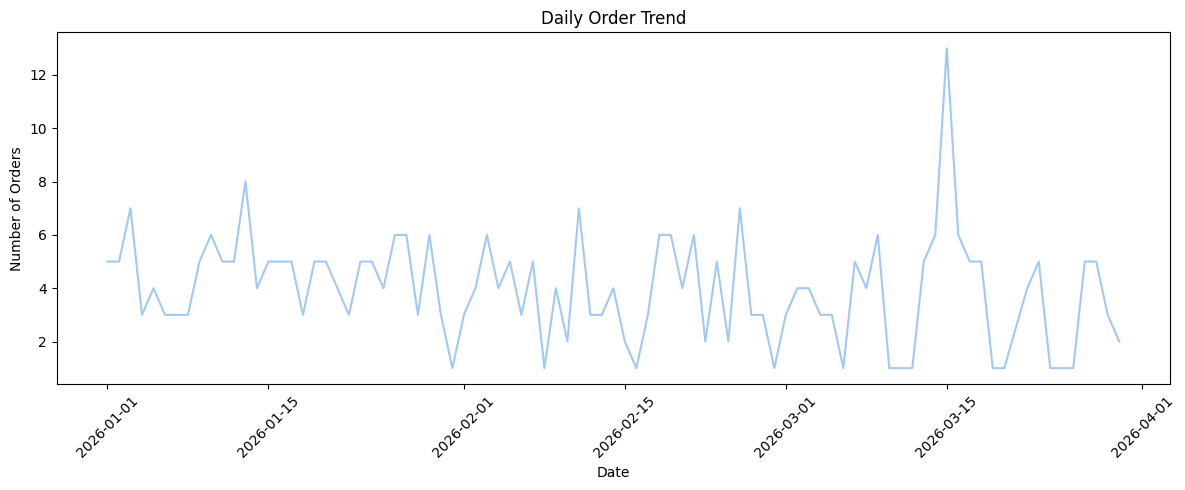

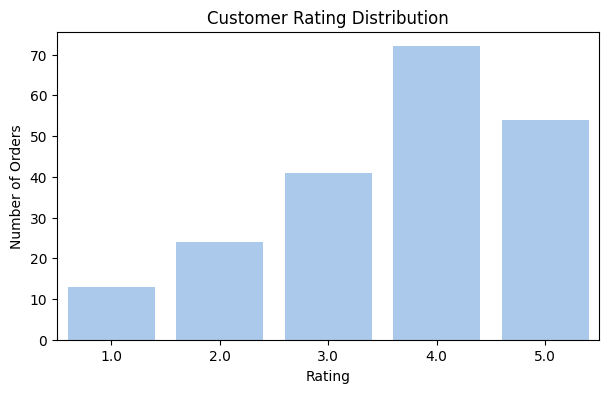

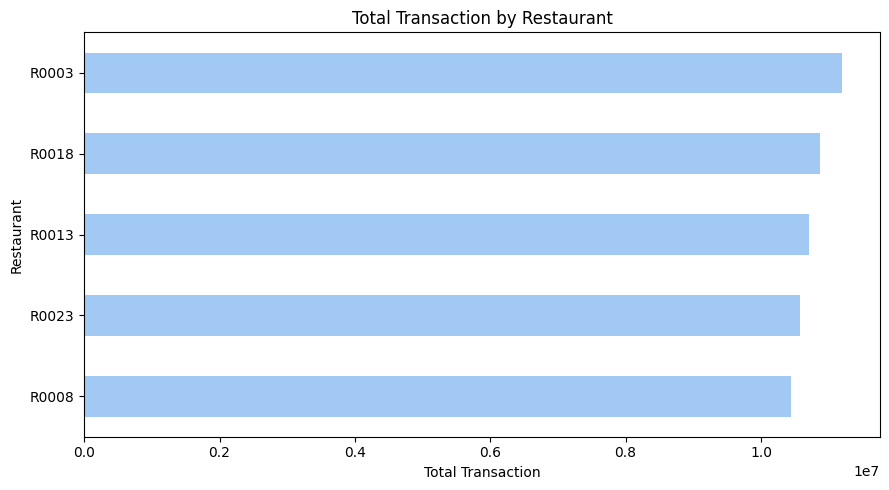

In [97]:
import matplotlib.pyplot as plt
import seaborn as sns

# Tren pesanan harian
plt.figure(figsize=(12, 5))
daily_orders.plot()
plt.title('Daily Order Trend')
plt.xlabel('Date')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Distribusi rating
plt.figure(figsize=(7, 4))
sns.countplot(data=df_final_flat, x='rating')
plt.title('Customer Rating Distribution')
plt.xlabel('Rating')
plt.ylabel('Number of Orders')
plt.show()

# Perbandingan transaksi restoran
plt.figure(figsize=(9, 5))
restaurant_analysis.sort_values('total_transaksi')['total_transaksi'].plot(
    kind='barh'
)
plt.title('Total Transaction by Restaurant')
plt.xlabel('Total Transaction')
plt.ylabel('Restaurant')
plt.tight_layout()
plt.show()

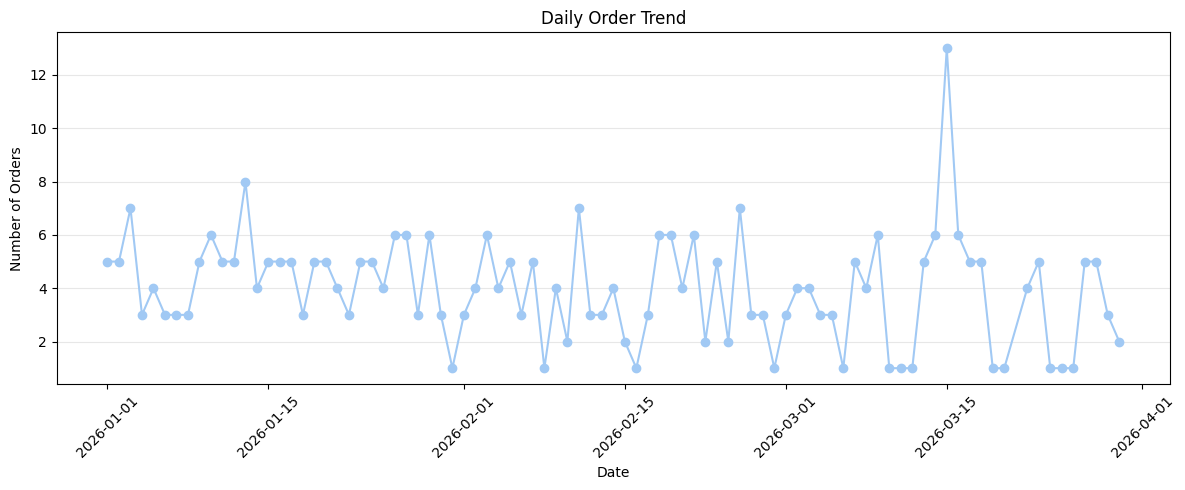

In [98]:
daily_orders.plot(marker='o', figsize=(12, 5))

plt.title('Daily Order Trend')
plt.xlabel('Date')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Pertanyaan bisnis
Bagaimana pola jumlah pesanan harian SwiftBite selama periode pengamatan?
Temuan dari grafik
1. Jumlah pesanan harian berfluktuasi. Sebagian besar hari mencatat sekitar 3–6 pesanan.
2. Puncak pesanan terjadi sekitar 15 Maret 2026, dengan 13 pesanan dalam satu hari.
3. Pada beberapa hari, jumlah pesanan hanya mencapai 1 pesanan.
4. Tidak terlihat tren kenaikan atau penurunan harian yang konsisten sepanjang periode pengamatan.
Kesimpulan
Jumlah pesanan harian SwiftBite cenderung berfluktuasi, dengan lonjakan tertinggi pada pertengahan Maret. Pola ini menunjukkan bahwa permintaan harian belum stabil selama periode pengamatan.

Saran kecil untuk grafik: tambahkan marker agar titik jumlah pesanan setiap tanggal lebih mudah dibaca.

In [99]:
completed_data = df_final_flat[
    df_final_flat['order_status'] == 'completed'
]

# Kinerja berdasarkan restoran
restaurant_performance = completed_data.groupby('restaurant_id').agg(
    jumlah_pesanan=('order_id', 'nunique'),
    total_transaksi=('total_amount', 'sum'),
    rata_rata_transaksi=('total_amount', 'mean')
).round(2).reset_index()

display(restaurant_performance.sort_values(
    'total_transaksi', ascending=False
))

# Kinerja berdasarkan segmen pelanggan
segment_performance = completed_data.groupby('customer_segment').agg(
    jumlah_pesanan=('order_id', 'nunique'),
    total_transaksi=('total_amount', 'sum'),
    rata_rata_transaksi=('total_amount', 'mean')
).round(2).reset_index()

display(segment_performance.sort_values(
    'total_transaksi', ascending=False
))

,restaurant_id,jumlah_pesanan,total_transaksi,rata_rata_transaksi
0,R0003,64,10276000,160562.50
3,R0018,64,10212000,159562.50
2,R0013,63,9870000,156666.67
1,R0008,63,9571000,151920.63
4,R0023,64,9502000,148468.75


,customer_segment,jumlah_pesanan,total_transaksi,rata_rata_transaksi
0,Loyal,106,16960000,160000.00
1,New,105,16783000,159838.10
2,Regular,107,15688000,146616.82


A3. Apakah terdapat perbedaan kinerja berdasarkan restoran dan segmen pelanggan?
1. Berdasarkan restoran
- R0003 mencatat total transaksi tertinggi sebesar Rp10.276.000, dengan 64 pesanan.
- R0018 berada di posisi kedua sebesar Rp10.212.000.
- R0023 memiliki total transaksi terendah sebesar Rp9.502.000.
- Jumlah pesanan antarrestoran relatif merata, yaitu 63–64 pesanan.
2. Berdasarkan segmen pelanggan
- Segmen Loyal menghasilkan total transaksi tertinggi sebesar Rp16.960.000.
- Segmen Regular memiliki jumlah pesanan terbanyak (107), tetapi rata-rata transaksinya paling rendah, yaitu Rp146.617.
- Segmen New menghasilkan rata-rata transaksi Rp159.838, hampir sama dengan segmen Loyal sebesar Rp160.000.
Kesimpulan:

Kinerja transaksi antarrestoran relatif merata. Sementara itu, segmen Loyal menghasilkan total transaksi tertinggi, meskipun jumlah pesanannya sedikit lebih rendah dibandingkan segmen Regular.

## **B. Kinerja Pengiriman**
1. Seberapa baik SwiftBite memenuhi estimasi waktu pengiriman?

In [100]:
# Ambil pesanan yang memiliki data durasi aktual dan estimasi
delivery_data = df_final_flat[
    (df_final_flat['order_status'] == 'completed') &
    (df_final_flat['actual_delivery_minutes'].notna()) &
    (df_final_flat['promised_delivery_minutes'].notna())
].copy()

# Hitung selisih waktu pengiriman
delivery_data['delay_minutes'] = (
    delivery_data['actual_delivery_minutes'] -
    delivery_data['promised_delivery_minutes']
)

# Kategorisasi ketepatan waktu
delivery_data['delivery_performance'] = delivery_data[
    'delay_minutes'
].apply(lambda x: 'Late' if x > 0 else 'On Time')

# Ringkasan kinerja pengiriman
delivery_summary = delivery_data['delivery_performance'].value_counts()

delivery_result = pd.DataFrame({
    'jumlah_pesanan': delivery_summary,
    'persentase': delivery_summary / len(delivery_data) * 100
}).round(2)

display(delivery_result)

# Statistik durasi pengiriman
display(
    delivery_data[
        ['actual_delivery_minutes', 'promised_delivery_minutes', 'delay_minutes']
    ].describe().round(2)
)

,jumlah_pesanan,persentase
delivery_performance,,
On Time,280,88.05
Late,38,11.95


,actual_delivery_minutes,promised_delivery_minutes,delay_minutes
count,318.00,318.00,318.00
mean,29.23,45.51,-16.28
std,15.13,8.71,12.12
min,5.00,30.00,-37.00
25%,17.25,38.00,-25.00
50%,26.50,45.00,-19.00
75%,39.75,53.00,-10.00
max,81.00,60.00,32.00


B1. Seberapa baik SwiftBite memenuhi estimasi waktu pengiriman?
Temuan berdasarkan data:
- Sebanyak 280 pesanan (88,05%) berhasil dikirim sesuai estimasi waktu.
- Sebanyak 38 pesanan (11,95%) mengalami keterlambatan.
- Rata-rata durasi aktual pengiriman adalah 29,23 menit, lebih cepat dibandingkan estimasi 45,51 menit.
- Median keterlambatan sebesar -19 menit, artinya separuh pesanan selesai setidaknya 19 menit lebih cepat dari estimasi.
- Keterlambatan terlama mencapai 32 menit.
Kesimpulan:

Secara umum, SwiftBite memiliki tingkat ketepatan waktu pengiriman yang cukup tinggi, dengan 88,05% pesanan selesai sesuai atau lebih cepat dari estimasi. Namun, masih terdapat 11,95% pesanan yang mengalami keterlambatan.

2. Apakah jarak pengiriman berkaitan dengan durasi dan keterlambatan?

In [101]:
# Kategorisasi jarak pengiriman
delivery_data['distance_category'] = pd.cut(
    delivery_data['distance_km'],
    bins=[0, 2, 5, 10, float('inf')],
    labels=['0-2 km', '2-5 km', '5-10 km', '>10 km']
)

# Analisis berdasarkan kategori jarak
distance_analysis = delivery_data.groupby(
    'distance_category', observed=False
).agg(
    jumlah_pesanan=('order_id', 'nunique'),
    rata_rata_durasi=('actual_delivery_minutes', 'mean'),
    rata_rata_keterlambatan=('delay_minutes', 'mean'),
    jumlah_terlambat=('delivery_performance',
                      lambda x: (x == 'Late').sum())
).round(2).reset_index()

distance_analysis['persentase_terlambat'] = (
    distance_analysis['jumlah_terlambat'] /
    distance_analysis['jumlah_pesanan'] * 100
).round(2)

display(distance_analysis)

,distance_category,jumlah_pesanan,rata_rata_durasi,rata_rata_keterlambatan,jumlah_terlambat,persentase_terlambat
0,0-2 km,25,24.16,-19.24,1,4.00
1,2-5 km,66,30.83,-15.62,9,13.64
2,5-10 km,114,30.46,-15.49,16,14.04
3,>10 km,113,28.17,-16.81,12,10.62


=== MATRIKS KORELASI PEARSON ===


,distance_km,actual_delivery_minutes,delay_minutes
distance_km,1.000,0.003,0.016
actual_delivery_minutes,0.003,1.000,0.818
delay_minutes,0.016,0.818,1.000


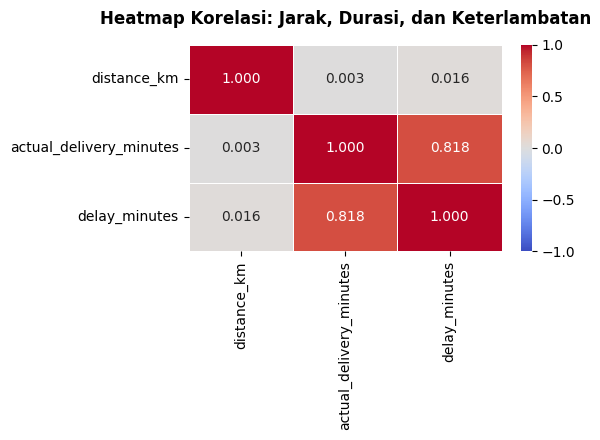

In [108]:
# 1. Menghitung matriks korelasi Pearson antar variabel numerik relevan
correlation_matrix = delivery_data[[
    'distance_km',
    'actual_delivery_minutes',
    'delay_minutes'
]].corr()

print("=== MATRIKS KORELASI PEARSON ===")
display(correlation_matrix.round(3))

# 2. Visualisasi Heatmap Korelasi
plt.figure(figsize=(6, 4.5))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".3f",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)
plt.title('Heatmap Korelasi: Jarak, Durasi, dan Keterlambatan', fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

 **Panduan Interpretasi Nilai Korelasi (Pearson r):**
*   **0.70 s/d 1.00** atau **-0.70 s/d -1.00**: Hubungan sangat kuat.
*   **0.40 s/d 0.69** atau **-0.40 s/d -0.69**: Hubungan moderat/sedang.
*   **0.10 s/d 0.39** atau **-0.10 s/d -0.39**: Hubungan lemah.
*   **Mendekati 0.00**: Tidak ada hubungan linear.



Interpretasi:
- Pengiriman jarak 0–2 km memiliki rata-rata durasi paling singkat, yaitu 24,16 menit, serta persentase keterlambatan terendah (4%).
- Pada jarak 2–5 km dan 5–10 km, persentase keterlambatan meningkat menjadi 13,64% dan 14,04%.
- Menariknya, pengiriman di atas 10 km justru memiliki rata-rata durasi 28,17 menit dan persentase keterlambatan 10,62%, lebih rendah dibandingkan kelompok 2–10 km.
- Seluruh kelompok memiliki rata-rata keterlambatan negatif, artinya rata-rata pesanan tetap tiba lebih awal daripada estimasi waktu pengiriman.
Kesimpulan: Jarak 0–2 km cenderung memiliki kinerja pengiriman terbaik. Namun, jarak yang lebih jauh tidak selalu menghasilkan durasi atau keterlambatan yang lebih tinggi. Kelompok 2–10 km justru menunjukkan persentase keterlambatan tertinggi.

jarak pengiriman belum dapat dianggap sebagai satu-satunya faktor yang menentukan keterlambatan.

3. Restoran atau zona mana yang menunjukkan tingkat keterlambatan lebih tinggi?

In [102]:
restaurant_delay = delivery_data.groupby('restaurant_name').agg(
    jumlah_pesanan=('order_id', 'nunique'),
    jumlah_terlambat=('delivery_performance',
                      lambda x: (x == 'Late').sum()),
    rata_rata_durasi=('actual_delivery_minutes', 'mean')
).reset_index()

restaurant_delay['persentase_terlambat'] = (
    restaurant_delay['jumlah_terlambat'] /
    restaurant_delay['jumlah_pesanan'] * 100
).round(2)

restaurant_delay = restaurant_delay.sort_values(
    'persentase_terlambat', ascending=False
).round(2)

display(restaurant_delay)

,restaurant_name,jumlah_pesanan,jumlah_terlambat,rata_rata_durasi,persentase_terlambat
1,SwiftBite Partner 08,63,9,27.25,14.29
4,SwiftBite Partner 23,64,9,27.61,14.06
2,SwiftBite Partner 13,63,8,30.57,12.70
3,SwiftBite Partner 18,64,7,30.77,10.94
0,SwiftBite Partner 03,64,5,29.92,7.81


In [103]:
zone_delay = delivery_data.groupby('customer_zone').agg(
    jumlah_pesanan=('order_id', 'nunique'),
    jumlah_terlambat=('delivery_performance',
                      lambda x: (x == 'Late').sum()),
    rata_rata_durasi=('actual_delivery_minutes', 'mean')
).reset_index()

zone_delay['persentase_terlambat'] = (
    zone_delay['jumlah_terlambat'] /
    zone_delay['jumlah_pesanan'] * 100
).round(2)

zone_delay = zone_delay.sort_values(
    'persentase_terlambat', ascending=False
).round(2)

display(zone_delay)

,customer_zone,jumlah_pesanan,jumlah_terlambat,rata_rata_durasi,persentase_terlambat
1,East,40,8,29.50,20.00
2,North,79,12,30.47,15.19
0,Central,27,3,28.33,11.11
3,South,53,5,29.19,9.43
4,West,119,10,28.53,8.40


Interpretasi:
- East memiliki tingkat keterlambatan tertinggi sebesar 20%, meskipun jumlah pesanannya bukan yang terbanyak.
- North mencatat jumlah pesanan terlambat terbanyak, yaitu 12 pesanan, dengan persentase 15,19%.
- West memiliki jumlah pesanan terbanyak (119), tetapi persentase keterlambatannya paling rendah, yaitu 8,40%.
Kesimpulan B3:

SwiftBite Partner 08 dan Partner 23 merupakan restoran dengan persentase keterlambatan tertinggi. Sementara itu, berdasarkan zona, East memiliki tingkat keterlambatan tertinggi sebesar 20%, diikuti North sebesar 15,19%. Kedua area tersebut dapat menjadi prioritas evaluasi untuk meningkatkan ketepatan waktu pengiriman.

## **C. Pengalaman Pelanggan**
1. Bagaimana tingkat kepuasan pelanggan berdasarkan rating dan ulasan?

=== RINGKASAN KEPUASAN PELANGGAN ===
Rata-rata Rating  : 3.64 / 5.00
Median Rating     : 4
Jumlah Rating Ada : 204 dari 350 pesanan
Persentase Review : 58.29%

=== DISTRIBUSI RATING LABEL ===


,Jumlah Pesanan
rating_label,
1 - Very Dissatisfied,13
2 - Dissatisfied,24
3 - Neutral,41
4 - Satisfied,72
5 - Very Satisfied,54
No Rating,146


/tmp/ipykernel_2712/2749832393.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


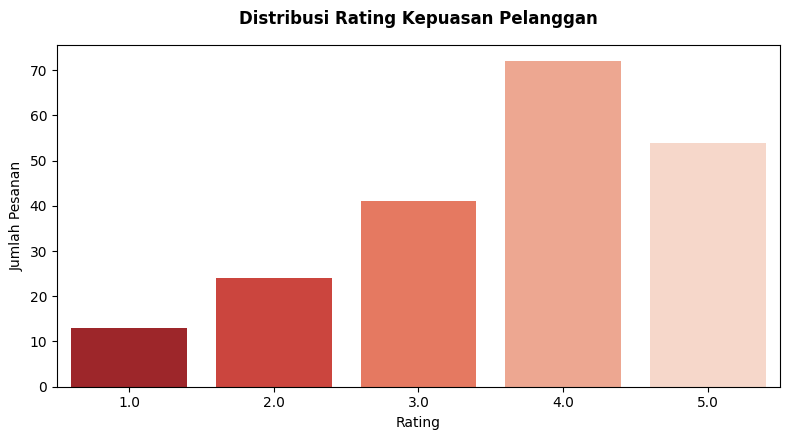

In [109]:
# 1. Statistik Deskriptif untuk Rating
avg_rating = df_final_flat['rating'].mean()
median_rating = df_final_flat['rating'].median()
total_reviews_count = df_final_flat['rating'].count()
pct_has_review = df_final_flat['has_review'].mean() * 100

print("=== RINGKASAN KEPUASAN PELANGGAN ===")
print(f"Rata-rata Rating  : {avg_rating:.2f} / 5.00")
print(f"Median Rating     : {median_rating:.0f}")
print(f"Jumlah Rating Ada : {total_reviews_count} dari {len(df_final_flat)} pesanan")
print(f"Persentase Review : {pct_has_review:.2f}%\n")

# 2. Distribusi Rating Detail
distribusi_rating = df_final_flat['rating_label'].value_counts().sort_index()
print("=== DISTRIBUSI RATING LABEL ===")
display(distribusi_rating.to_frame('Jumlah Pesanan'))

# 3. Visualisasi Distribusi Rating
plt.figure(figsize=(8, 4.5))
custom_colors = ['#790D16', '#AEC4D4', '#E5D3AF', '#4D8DBA', '#F4AE52']
sns.countplot(
    data=df_final_flat.dropna(subset=['rating']),
    x='rating',
    palette='Reds_r'
)
plt.title('Distribusi Rating Kepuasan Pelanggan', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Rating', fontsize=10)
plt.ylabel('Jumlah Pesanan', fontsize=10)
plt.tight_layout()
plt.show()

Rata-rata Rating: 3.64 / 5.00 (Menunjukkan tingkat kepuasan umum yang berada di kategori cukup baik/moderat).
Median Rating: 4 (Sebagian besar pelanggan yang memberikan ulasan merasa Puas).
Tingkat Partisipasi Ulasan: Baru 58.29% dari keseluruhan pesanan yang memberikan ulasan (204 dari 350 pesanan), sedangkan 41.71% pesanan (146 pesanan) tidak menyertakan rating/ulasan (No Rating).

Pelanggan yang pesanannya terlambat memberikan rata-rata rating sebesar 2.80, jauh lebih rendah dibandingkan pesanan yang tepat waktu dengan rata-rata rating 3.75 (selisih 0.95 poin). Hal ini menunjukkan bahwa performa pengiriman sangat sensitif terhadap penilaian kepuasan pelanggan.

In [104]:
rating_delay = delivery_data.groupby('delivery_performance').agg(
    jumlah_pesanan=('order_id', 'nunique'),
    rata_rata_rating=('rating', 'mean'),
    median_rating=('rating', 'median')
).round(2).reset_index()

display(rating_delay)

,delivery_performance,jumlah_pesanan,rata_rata_rating,median_rating
0,Late,38,2.80,3.0
1,On Time,280,3.75,4.0


Interpretasi:
- Pesanan yang terlambat memiliki rata-rata rating 2,80, lebih rendah dibandingkan pesanan tepat waktu sebesar 3,75.
- Median rating pesanan terlambat adalah 3, sedangkan pesanan tepat waktu adalah 4.
- Terdapat selisih rata-rata rating sebesar 0,95 poin.
Kesimpulan: Pesanan yang mengalami keterlambatan cenderung memperoleh rating lebih rendah. Hal ini menunjukkan adanya keterkaitan antara ketepatan waktu pengiriman dan kepuasan pelanggan. Namun, hasil ini belum membuktikan bahwa keterlambatan merupakan satu-satunya penyebab penurunan rating.

3. Segmen pelanggan mana yang memberikan penilaian berbeda?

In [105]:
segment_rating = df_final_flat.groupby('customer_segment').agg(
    jumlah_rating=('rating', 'count'),
    rata_rata_rating=('rating', 'mean'),
    median_rating=('rating', 'median')
).round(2).reset_index()

display(segment_rating)

,customer_segment,jumlah_rating,rata_rata_rating,median_rating
0,Loyal,69,3.83,4.0
1,New,67,3.46,4.0
2,Regular,68,3.62,4.0


Interpretasi:
- Segmen Loyal memberikan penilaian tertinggi dengan rata-rata 3,83.
- Segmen Regular memiliki rata-rata rating 3,62.
- Segmen New memberikan penilaian terendah dengan rata-rata 3,46.
- Meskipun rata-rata rating berbeda, ketiga segmen memiliki median yang sama, yaitu 4.
Kesimpulan: Pelanggan Loyal cenderung memberikan penilaian lebih tinggi dibandingkan segmen New dan Regular. Namun, perbedaan rata-rata rating antarsemen relatif kecil.

## **D. Kinerja Pembayaran**
Bagaimana tingkat keberhasilan, kegagalan, dan pengembalian pembayaran?


In [110]:
payment_analysis = df_final_flat['payment_status'].value_counts().reset_index()

payment_analysis.columns = ['status_pembayaran', 'jumlah_transaksi']

payment_analysis['persentase'] = (
    payment_analysis['jumlah_transaksi'] /
    payment_analysis['jumlah_transaksi'].sum() * 100
).round(2)

display(payment_analysis)

,status_pembayaran,jumlah_transaksi,persentase
0,successful,318,90.86
1,failed,21,6.00
2,refunded,11,3.14


Interpretasi:
- Sebanyak 318 transaksi (90,86%) berhasil dibayarkan.
- Sebanyak 21 transaksi (6%) mengalami kegagalan pembayaran.
- Sebanyak 11 transaksi (3,14%) mengalami pengembalian dana (refunded).
Kesimpulan: Tingkat keberhasilan pembayaran SwiftBite tergolong tinggi, yaitu 90,86%. Namun, masih terdapat 9,14% transaksi yang gagal atau mengalami pengembalian dana sehingga perlu diperhatikan.

In [106]:
payment_method_analysis = df_final_flat.groupby(
    ['payment_method', 'payment_status']
).size().unstack(fill_value=0)

payment_method_analysis['total_transaksi'] = (
    payment_method_analysis.sum(axis=1)
)

payment_method_analysis['success_rate'] = (
    payment_method_analysis.get('successful', 0) /
    payment_method_analysis['total_transaksi'] * 100
).round(2)

display(payment_method_analysis)

payment_status,failed,refunded,successful,total_transaksi,success_rate
payment_method,,,,,
bank_transfer,5,3,80,88,90.91
cash,5,3,79,87,90.80
credit_card,6,2,79,87,90.80
e_wallet,5,3,80,88,90.91


Interpretasi:
- Bank transfer dan e-wallet memiliki tingkat keberhasilan tertinggi, yaitu 90,91%.
- Cash dan credit card memiliki tingkat keberhasilan sebesar 90,80%.
- Credit card mencatat kegagalan pembayaran terbanyak, yaitu 6 transaksi.
- Perbedaan tingkat keberhasilan antarmetode sangat kecil, hanya 0,11 poin persentase.
Kesimpulan: Tidak terlihat perbedaan yang berarti dalam tingkat keberhasilan pembayaran berdasarkan metode yang digunakan. Keempat metode memiliki performa pembayaran yang relatif konsisten.

In [107]:
failed_payment = df_final_flat[
    df_final_flat['payment_status'] == 'failed'
]

failed_payment_analysis = failed_payment['attempt_number'].agg(
    ['count', 'mean', 'median', 'min', 'max']
).round(2)

display(failed_payment_analysis)

,attempt_number
count,21.0
mean,1.0
median,1.0
min,1.0
max,1.0


Interpretasi:
- Terdapat 21 transaksi yang mengalami kegagalan pembayaran.
- Seluruh transaksi gagal tercatat hanya memiliki satu kali percobaan pembayaran.
- Tidak ditemukan variasi jumlah percobaan pada transaksi gagal.
Kesimpulan: Seluruh transaksi yang gagal terjadi pada percobaan pertama. Berdasarkan data ini, belum terlihat adanya percobaan ulang (retry) pada transaksi yang gagal